Código adaptado de:

[1] O. Sanseviero, P. Cuenca, A. Passos e J. Whitaker, Hands-On Generative AI with Transformers and Diffusion Models, O'Reilly, 2024.

[2] A. Géron, Hands-On Machine Learning with Scikit-Learn, Keras & TensorFlow, Third Edition, O'Reilly, 2022.

[3] Documentação da biblioteca [`diffusers`](https://huggingface.co/docs/diffusers), do Hugging Face.

# Laboratório 10: Modelos de Difusão com Hugging Face (imagens)

## Integrantes do Grupo

- ERICKSON LINS LIMEIRA - Matrícula 20260039784
- GIL CÉSAR FARIA - Matrícula 20250082520

## Importações

In [1]:
!pip install -q diffusers datasets torchinfo                                    # Difusão, conjuntos do Hub e sumário de modelos

In [2]:
from __future__ import annotations                                              # Anotações de tipo adiadas
import os                                                                       # Arquivos locais
import time                                                                     # Duração do treinamento e da geração
from typing import NamedTuple                                                   # Histórico de treinamento
import gdown                                                                    # Download do Google Drive
from tqdm.auto import tqdm                                                      # Barra de progresso
import numpy as np                                                              # Operações numéricas
import pandas as pd                                                             # Tabelas de resultados
from matplotlib import pyplot as plt                                            # Gráficos
import torch                                                                    # PyTorch
import torch.nn.functional as F                                                 # Funções de perda
import torch.optim as optim                                                     # Otimizadores (AdamW)
from torch.utils.data import DataLoader                                         # Mini-lotes
from torchvision import transforms                                              # Pré-processamento de imagens
from torchinfo import summary                                                   # Sumário de modelos
import datasets                                                                 # Conjuntos de dados do Hugging Face Hub
import diffusers                                                                # Modelos de difusão do Hugging Face
import huggingface_hub                                                          # Download de modelos e dados do Hub
from datasets import load_dataset                                               # Carrega um conjunto do Hub
from diffusers import DDPMScheduler, UNet2DModel, DDPMPipeline                  # Agendador, U-Net e pipeline do DDPM

In [3]:
datasets.logging.set_verbosity_error()                                          # Silencia os avisos do datasets
diffusers.logging.set_verbosity_error()                                         # Silencia os avisos do diffusers
huggingface_hub.logging.set_verbosity_error()                                   # Silencia os avisos do Hub

In [4]:
plt.rcParams.update({
    "text.usetex": False,
    "mathtext.fontset": "stix",
    "font.family": "STIXGeneral",
})

## Funções auxiliares para visualização

In [5]:
UTILS_URL = ("https://drive.google.com/file/d/1gnzKZr0UoYErRb3Yxmzftwfds1dDu2ev/view?usp=sharing")
if not os.path.exists("diffusion_hf_utils.py"):                                 # Baixa só se ainda não existir
    try:
        gdown.download(UTILS_URL, "diffusion_hf_utils.py", quiet=True)
    except Exception as error:
        print(f"Falha no download de diffusion_hf_utils.py: {error}")

from diffusion_hf_utils import (                                                # Funções auxiliares
    animate_forward_process, animate_reverse_process, animate_snapshots,
    compare_noise_schedules, compare_processes, compare_training_curves,
    plot_forward_process, plot_interpolation, plot_noise_and_denoise,
    plot_noise_schedule, plot_pixel_histogram, plot_reverse_process,
    plot_snapshots, plot_steps_comparison, plot_time_encoding,
    plot_training_curve, plot_training_example, show_figure, show_images,
)

## Hiperparâmetros

| Hiperparâmetro | Descrição |
|---|---|
| `DEVICE` | dispositivo de execução: GPU, se houver, ou CPU |
| `SEED` | semente dos dados, dos modelos e das amostras |
| `DATASET_NAME` | conjunto de imagens no Hugging Face Hub |
| `IMAGE_SIZE` | lado das imagens, em pixels |
| `NUM_CHANNELS` | número de canais das imagens ($3$, RGB) |
| `BATCH_SIZE` | tamanho do mini-lote de treinamento |
| `NUM_TRAIN_TIMESTEPS` | número de passos de difusão $T$ |
| `BETA_SCHEDULE` | cronograma de ruído: `"linear"` ou `"squaredcos_cap_v2"` (cosseno) |
| `BLOCK_OUT_CHANNELS` | número de canais de cada nível da U-Net |
| `DOWN_BLOCK_TYPES` | tipo de cada nível do codificador da U-Net |
| `UP_BLOCK_TYPES` | tipo de cada nível do decodificador da U-Net |
| `LAYERS_PER_BLOCK` | blocos residuais por nível da U-Net |
| `NUM_EPOCHS` | número de épocas de treinamento |
| `LEARNING_RATE` | taxa de aprendizado do AdamW, constante |
| `SNAPSHOT_EVERY` | intervalo, em épocas, entre as imagens geradas durante o treinamento |
| `NUM_SAMPLES_GEN` | número de imagens geradas nas visualizações |
| `CLIP_SAMPLE` | recorte de $\hat{\mathbf{x}}_0$ em $[-1, 1]$ no passo reverso |
| `VARIANCE_TYPE` | variância $\sigma_t^2$ do passo reverso: `"fixed_small"` (padrão do `diffusers`), $\sigma_t^2 = \frac{1 - \bar{\alpha}_{t-1}}{1 - \bar{\alpha}_t}\,\beta_t$, ou `"fixed_large"`, $\sigma_t^2 = \beta_t$ |

In [6]:
DEVICE = (torch.accelerator.current_accelerator().type                          # GPU, se houver; senão, CPU
          if torch.accelerator.is_available() else "cpu")
SEED = 42                                                                       # Semente dos dados, modelos e amostras
DATASET_NAME = "huggan/flowers-102-categories"                                  # Oxford Flowers 102 no Hub (8189 imagens)
IMAGE_SIZE = 64                                                                 # Imagens 64 x 64
NUM_CHANNELS = 3                                                                # RGB
BATCH_SIZE = 64                                                                 # Tamanho do mini-lote
NUM_TRAIN_TIMESTEPS = 1_000                                                     # Número de passos de difusão T
BETA_SCHEDULE = "squaredcos_cap_v2"                                             # Cronograma cosseno ("linear" é o outro)
BLOCK_OUT_CHANNELS = (32, 64, 96, 128)                                          # Canais nos níveis de 64, 32, 16 e 8 pixels
DOWN_BLOCK_TYPES = ("DownBlock2D", "DownBlock2D", "DownBlock2D", "DownBlock2D") # Codificador
UP_BLOCK_TYPES = ("UpBlock2D", "UpBlock2D", "UpBlock2D", "UpBlock2D")           # Decodificador
LAYERS_PER_BLOCK = 2                                                            # Blocos residuais por nível
NUM_EPOCHS = 50                                                                 # Épocas de treinamento
LEARNING_RATE = 1e-4                                                            # Taxa de aprendizado do AdamW
SNAPSHOT_EVERY = 5                                                              # Imagens geradas a cada 5 épocas
NUM_SAMPLES_GEN = 16                                                            # Imagens geradas nas visualizações
CLIP_SAMPLE = True                                                              # Recorte de x̂_0 em [-1, 1] no passo reverso (padrão: True)
VARIANCE_TYPE = "fixed_large"                                                   # "fixed_large": σ_t² = β_t (padrão: "fixed_small")

In [7]:
print(f"Usando {DEVICE}.")

Usando mps.


## Dados

Imagens de flores do [Oxford Flowers 102](https://www.robots.ox.ac.uk/~vgg/data/flowers/102/), baixado do [Hugging Face Hub](https://huggingface.co/datasets/huggan/flowers-102-categories).

- **Dados:** $\mathbf{x}_0 \in \mathbb{R}^{3 \times 64 \times 64}$, as $8189$ imagens RGB do conjunto;
- **Escala:** os pixels são normalizados no intervalo $[-1, 1]$, uma escala comparável à de $\mathcal{N}(\mathbf{0}, \mathbf{I})$;
- **Distribuição a priori:** $\mathcal{N}(\mathbf{0}, \mathbf{I})$, onde o processo direto termina e o processo reverso começa;
- **Treinamento:** mini-lotes embaralhados (`train_dl`).

A biblioteca `datasets`, do Hugging Face, prepara os dados em três etapas:

| Etapa | Ferramenta | Descrição |
|---|---|---|
| 1 | `load_dataset` | baixa o conjunto do Hub na primeira vez e o guarda em cache, no disco |
| 2 | `dataset.map` | redimensiona e recorta as imagens uma única vez; o resultado também fica em cache |
| 3 | `dataset.set_transform` | a cada leitura, espelha a imagem ao acaso, converte em tensor e normaliza os pixels no intervalo $[-1, 1]$ |

O `DataLoader`, do PyTorch, monta os mini-lotes.

In [8]:
dataset = load_dataset(DATASET_NAME, split="train")                             # Baixa do Hub na 1ª vez; depois, usa o cache

In [9]:
print(dataset)                                                                  # Colunas e número de imagens

Dataset({
    features: ['image'],
    num_rows: 8189
})


In [10]:
# Feito uma única vez: decodificar e reduzir as fotos grandes a cada época deixaria o treinamento lento.
# O espelhamento aleatório fica na próxima célula, porque precisa ser sorteado de novo a cada leitura.
resize_crop = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),                                              # Lado menor com 64 px, sem deformar
    transforms.CenterCrop(IMAGE_SIZE),                                          # Corta as bordas do lado maior: 64 x 64
])


def resize_images(examples):
    """Redimensiona e recorta um lote de imagens PIL (chamada pelo map, uma única vez)."""
    examples["image"] = [resize_crop(image.convert("RGB"))                      # Garante 3 canais (RGB) e reduz
                         for image in examples["image"]]
    return examples                                                             # Mesmo formato, imagens já pequenas


dataset = dataset.map(resize_images, batched=True)                              # Roda uma vez; o resultado vai ao cache

In [11]:
augment = transforms.Compose([
    transforms.RandomHorizontalFlip(),                                          # Espelhamento aleatório (aumento de dados)
    transforms.ToTensor(),                                                      # PIL -> tensor (C, H, W) em [0, 1]
    transforms.Normalize([0.5], [0.5]),                                         # [0, 1] -> [-1, 1]
])


def transform(examples):
    """Converte um lote do conjunto em tensores em [-1, 1], sob a chave "images"."""
    return {"images": [augment(image) for image in examples["image"]]}


dataset.set_transform(transform)                                                # Aplicada a cada leitura
train_dl = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True,             # Mini-lotes embaralhados
                      drop_last=True)

In [ ]:
torch.manual_seed(SEED)                                                         # Fixa o lote exibido
batch = next(iter(train_dl))                                                    # Um mini-lote: dicionário {"images": tensor}
x_batch = batch["images"]                                                       # Tensor (B, 3, 64, 64) em [-1, 1]
print(f"Lote: {tuple(x_batch.shape)}, mín. {x_batch.min():.2f}, máx. {x_batch.max():.2f}")
show_images(x_batch[:16], nrows=2, suptitle="Imagens de treinamento")           # 16 imagens do lote

Os pixels ficam em $[-1, 1]$, a mesma faixa em que se concentra boa parte da massa de $\mathcal{N}(0, 1)$: no kernel de difusão, a imagem e o ruído entram com magnitudes comparáveis.

In [ ]:
plot_pixel_histogram(x_batch)                                                   # Pixels do lote e densidade de N(0, 1)

## Modelo de difusão

Um modelo de difusão [*diffusion model*] aprende a gerar dados invertendo um processo que os destrói aos poucos:

- **processo direto** [*forward process*] $q$: fixo; adiciona ruído Gaussiano em $T$ passos e leva uma imagem $\mathbf{x}_0$ a $\mathbf{x}_T$, com distribuição aproximadamente $\mathcal{N}(\mathbf{0}, \mathbf{I})$;
- **processo reverso** [*reverse process*] $p_\theta$: aprendido por uma rede neural de parâmetros $\theta$; remove o ruído passo a passo, de $\mathbf{x}_T \sim \mathcal{N}(\mathbf{0}, \mathbf{I})$ até uma imagem $\mathbf{x}_0$.

In [ ]:
show_figure("processos_difusao")                                                # Processos direto e reverso numa imagem

O modelo é o DDPM [*denoising diffusion probabilistic model*], de [Ho et al. (2020)](https://arxiv.org/abs/2006.11239). Na biblioteca [`diffusers`](https://huggingface.co/docs/diffusers), do Hugging Face, cada peça já vem pronta:

| Peça | `diffusers` |
|---|---|
| Cronograma de ruído | `DDPMScheduler` |
| Kernel de difusão | `noise_scheduler.add_noise` |
| Rede preditora de ruído, com a codificação temporal | `UNet2DModel` |
| Passo reverso | `noise_scheduler.step` |
| Geração | `DDPMPipeline` |

### Um DDPM pré-treinado

Antes de treinar o nosso, um modelo já treinado: o DDPM original de [Ho et al. (2020)](https://arxiv.org/abs/2006.11239), o modelo [ddpm-celebahq-256](https://huggingface.co/google/ddpm-celebahq-256), treinado com o conjunto de dados [CelebA-HQ](https://www.tensorflow.org/datasets/catalog/celeb_a_hq) [(T. Karras et al., 2018)](https://arxiv.org/abs/1710.10196), de rostos em $256 \times 256$ pixels. Um *pipeline* reúne a rede e o agendador de ruído e gera imagens com uma única chamada.

In [ ]:
image_pipe = DDPMPipeline.from_pretrained("google/ddpm-celebahq-256",           # Baixa do Hub na 1ª vez (cerca de 450 MB)
                                          use_safetensors=False)                # O repositório só tem pesos .bin
image_pipe = image_pipe.to(DEVICE)                                              # Rede no dispositivo
image_pipe().images[0]                                                          # Uma imagem PIL: T = 1000 passos reversos

O *pipeline* empacota o laço do processo reverso. A célula abaixo escreve esse laço explicitamente com $30$ passos em vez de $1000$:

- `image` começa como $\mathbf{x}_T \sim \mathcal{N}(\mathbf{0}, \mathbf{I})$: $4$ imagens RGB de $256 \times 256$ pixels;
- `set_timesteps(num_inference_steps=30)` escolhe $30$ valores de $t$, de $957$ a $0$, de $33$ em $33$: cada passo reverso pula um trecho da cadeia.

A cada iteração `i`, com o passo `t`:

1. a U-Net prediz o ruído contido em $\mathbf{x}_t$: `noise_pred` $= \boldsymbol{\epsilon}_\theta(\mathbf{x}_t, t)$;
2. `image_pipe.scheduler.step(noise_pred, t, image)` aplica o passo reverso e devolve `scheduler_output`;
3. `image` recebe `scheduler_output.prev_sample`, a entrada da iteração seguinte;
4. a cada $10$ iterações, `plot_noise_and_denoise` mostra os dois campos de `scheduler_output` lado a lado.

`scheduler_output` é um objeto da classe `DDPMSchedulerOutput`, com dois campos:

| Campo | Nomenclatura | Descrição |
|---|---|---|
| `prev_sample` | $\mathbf{x}_{t'}$ | amostra do próximo passo da lista, $t' = t - 33$; na última iteração, a imagem gerada |
| `pred_original_sample` | $\hat{\mathbf{x}}_0$ | imagem limpa estimada a partir de $\mathbf{x}_t$ |

A imagem limpa estimada vem do kernel de difusão (vide processo direto): basta trocar o ruído $\boldsymbol{\epsilon}$ pelo ruído predito e isolar $\mathbf{x}_0$:
<br>
<br>
$$
\mathbf{x}_t = \sqrt{\bar{\alpha}_t}\,\mathbf{x}_0
+ \sqrt{1 - \bar{\alpha}_t}\,{\color{red}{\boldsymbol{\epsilon}}}
\quad \Longrightarrow \quad
\hat{\mathbf{x}}_0 =
\frac{1}{\sqrt{\bar{\alpha}_t}}\mathbf{x}_t
-
\frac{\sqrt{1 - \bar{\alpha}_t}}{\sqrt{\bar{\alpha}_t}}\,
{\color{red}{\boldsymbol{\epsilon}_\theta(\mathbf{x}_t, t)}}.
$$

In [ ]:
generator = torch.Generator().manual_seed(SEED)                                 # Semente fixa: x_T e os ruídos z se repetem a cada execução
image = torch.randn(4, 3, 256, 256, generator=generator).to(DEVICE)             # x_T ~ N(0, I): 4 imagens RGB de 256 x 256 pixels
image_pipe.scheduler.set_timesteps(num_inference_steps=30)                      # Escolhe 30 dos 1000 passos do treinamento
print(image_pipe.scheduler.timesteps)                                           # t = 957, 924, ..., 33, 0: de 33 em 33

for i, t in enumerate(image_pipe.scheduler.timesteps):                          # i: iteração, de 0 a 29; t: passo da cadeia
    with torch.inference_mode():                                                # Só inferência: sem cálculo de gradientes
        noise_pred = image_pipe.unet(image, t).sample                           # Ruído predito em x_t: ε_θ(x_t, t)
    scheduler_output = image_pipe.scheduler.step(noise_pred, t, image,          # Passo reverso: estima x̂_0 e calcula x_t',
                                                 generator=generator)           # somando o ruído novo z do gerador
    image = scheduler_output.prev_sample                                        # x_t', com t' = t - 33: entrada da próxima iteração
    if i % 10 == 0 or i == len(image_pipe.scheduler.timesteps) - 1:             # Nas iterações 0, 10, 20 e 29
        plot_noise_and_denoise(scheduler_output, i, t)                          # x_t' e x̂_0 lado a lado

No restante do laboratório, treinamos um modelo de difusão utilizando imagens de flores.

### Processo direto

Cada passo do processo direto multiplica a imagem do passo anterior por $\sqrt{1 - \beta_t}$ e soma ruído com variância $\beta_t$:
<br>
<br>
$$\boxed{\mathbf{x}_t = \sqrt{1 - \beta_t}\,\mathbf{x}_{t-1} + \sqrt{\beta_t}\,\boldsymbol{\epsilon}_t,  \qquad \boldsymbol{\epsilon}_t \sim \mathcal{N}(\mathbf{0}, \mathbf{I})}
\quad \iff \quad
q(\mathbf{x}_t \mid \mathbf{x}_{t-1}) = \mathcal{N}\left(\mathbf{x}_t ; \sqrt{1 - \beta_t}\,\mathbf{x}_{t-1},\ \beta_t \mathbf{I}\right),
\qquad t = 1, \ldots, T,$$
<br>

O **kernel de difusão** leva $\mathbf{x}_0$ diretamente a $\mathbf{x}_t$, sem percorrer os passos intermediários:
<br>
<br>
$$\boxed{\quad \mathbf{x}_t = \underbrace{\sqrt{\bar{\alpha}_t}}_{\substack{\text{fator de escala}\\\text{do sinal}}}\,
\cdot
\underbrace{\mathbf{x}_0 }_{\text{imagem}}
+ \underbrace{\sqrt{1 - \bar{\alpha}_t}}_{\substack{\text{fator de escala}\\\text{do ruído}}}\,
\cdot
\underbrace{\boldsymbol{\epsilon}}_{\text{ruído}}, \qquad \boldsymbol{\epsilon} \sim \mathcal{N}(\mathbf{0}, \mathbf{I})}
\iff
q(\mathbf{x}_t \mid \mathbf{x}_0) = \mathcal{N}\left(\mathbf{x}_t ; \sqrt{\bar{\alpha}_t}\,\mathbf{x}_0,\ (1 - \bar{\alpha}_t)\mathbf{I}\right) \quad
\qquad \alpha_t = 1 - \beta_t, \qquad \bar{\alpha}_t = \prod_{s=1}^{t} \alpha_s.$$

##### Cronograma de ruído

O `DDPMScheduler`:
- guarda $\beta_t$, $\alpha_t$ e $\bar{\alpha}_t$;
- aplica o kernel de difusão;
- na geração, aplica o passo reverso.

| Argumento | Valor | Descrição |
|---|---|---|
| `num_train_timesteps` | $1000$ | número de passos $T$ |
| `beta_schedule` | `"squaredcos_cap_v2"` | cronograma cosseno |
| `clip_sample` | `CLIP_SAMPLE` | recorte de $\hat{\mathbf{x}}_0$ no passo reverso |
| `variance_type` | `VARIANCE_TYPE` | variância $\sigma_t^2$ do passo reverso |

Os dois últimos só atuam na geração e aparecem em Processo reverso; os demais argumentos ficam com os valores padrão da biblioteca, como em [1].

| Atributo | Nomenclatura | Descrição.............................................................. |
|---|---|---|
| `betas` | $\beta_t$ | variância do ruído adicionado no passo $t$ |
| `alphas` | $\alpha_t$ | fração do sinal mantida no passo $t$ |
| `alphas_cumprod` | $\bar{\alpha}_t$ | nível do sinal em $\mathbf{x}_t$ |

> **Atenção:** a biblioteca numera os passos de $0$ a $T - 1$: o índice `t` do `diffusers` é o passo $t + 1$ das equações, e `alphas_cumprod[t]` é $\bar{\alpha}_{t+1}$. O código e as figuras usam os índices da biblioteca.

In [17]:
noise_scheduler = DDPMScheduler(
    num_train_timesteps=NUM_TRAIN_TIMESTEPS,                                    # Número de passos T
    beta_schedule=BETA_SCHEDULE,                                                # "linear" ou "squaredcos_cap_v2"
    clip_sample=CLIP_SAMPLE,                                                    # Recorte de x̂_0 no passo reverso
    variance_type=VARIANCE_TYPE,                                                # Variância σ_t² do passo reverso
)                                                                               # Demais argumentos: valores padrão

In [ ]:
plot_noise_schedule(noise_scheduler)

##### Kernel de difusão

`noise_scheduler.add_noise(x0, noise, t)` aplica o kernel de difusão a um lote, com um passo `t` por imagem.

In [ ]:
x0 = x_batch[:4]                                                                # 4 imagens limpas, (4, 3, 64, 64)
noise = torch.randn_like(x0)                                                    # ε ~ N(0, I)
t = torch.tensor([0, 250, 500, 999])                                            # Um passo por imagem
x_t = noise_scheduler.add_noise(x0, noise, t)                                   # Kernel de difusão
show_images(torch.cat([x0, x_t]), nrows=2,                                      # Original em cima, com ruído embaixo
            titles=[f"$t = {int(s)}$" for s in t] + [""] * len(t),              # t no alto de cada coluna
            row_labels=[r"$\mathbf{x}_0$", r"$\mathbf{x}_t$"])                  # Rótulos das linhas

Visualização do processo direto:

In [ ]:
plot_forward_process(x_batch[:4], noise_scheduler)                              # q(x_t) de t = 0 a t = T - 1

A animação mostra o mesmo processo, com os fatores de escala do sinal e do ruído em cada passo.

In [ ]:
animate_forward_process(x_batch[:4], noise_scheduler)

##### Cronogramas linear e cosseno

O cronograma de ruído [*noise schedule*] define o ritmo em que a imagem vira ruído. No cronograma linear do DDPM original, $\beta_t$ cresce linearmente de $10^{-4}$ a $0.02$; no cronograma cosseno ([Nichol e Dhariwal, 2021](https://arxiv.org/abs/2102.09672)), $\bar{\alpha}_t$ cai devagar no início e no fim da cadeia. As figuras comparam $\bar{\alpha}_t$ e a mesma flor nos dois cronogramas, com o mesmo $\boldsymbol{\epsilon}$:

In [ ]:
linear_scheduler = DDPMScheduler(num_train_timesteps=NUM_TRAIN_TIMESTEPS,       # β_t de 10^-4 a 0.02
                                 beta_schedule="linear")
cosine_scheduler = DDPMScheduler(num_train_timesteps=NUM_TRAIN_TIMESTEPS,       # ᾱ_t em forma de cosseno
                                 beta_schedule="squaredcos_cap_v2")
schedulers = {                                                                  # Dois cronogramas, com T = 1000
    "linear": linear_scheduler,
    "cosseno": cosine_scheduler,
}

compare_noise_schedules(schedulers, x_batch[0])                                 # ᾱ_t e a mesma flor nos dois cronogramas

### Processo reverso

- Para gerar imagens, é preciso inverter o processo direto, mas $q(\mathbf{x}_{t-1} \mid \mathbf{x}_t)$ é **intratável**. O processo reverso é modelado por $p_\theta(\mathbf{x}_{t-1} \mid \mathbf{x}_t)$ e cada passo reverso usa o ruído predito pela rede, $\boldsymbol{\epsilon}_\theta(\mathbf{x}_t, t)$:
$$\boxed{\mathbf{x}_{t-1} = \underbrace{\frac{1}{\sqrt{\alpha_t}}\left(\mathbf{x}_t - \frac{\beta_t}{\sqrt{1 - \bar{\alpha}_t}}\,{\color{red}{\boldsymbol{\epsilon}_\theta(\mathbf{x}_t, t)}}\right)}_{\text{média: } \boldsymbol{\mu}_\theta(\mathbf{x}_t, t)} + \underbrace{\sigma_t\,\mathbf{z}}_{\text{ruído novo}}, \qquad \mathbf{z} \sim \mathcal{N}(\mathbf{0}, \mathbf{I})}
\quad \iff \quad
p_\theta(\mathbf{x}_{t-1} \mid \mathbf{x}_t) = \mathcal{N}\left(\mathbf{x}_{t-1} ; \boldsymbol{\mu}_\theta(\mathbf{x}_t, t),\ \sigma_t^2 \mathbf{I}\right),$$
com $\mathbf{z} = \mathbf{0}$ no último passo ($t = 1$). A variância $\sigma_t^2$ é definida conforme o hiperparâmetro `VARIANCE_TYPE`.

- No `diffusers`, a rede é a `UNet2DModel` (próxima seção), e o passo reverso é `noise_scheduler.step(noise_pred, t, x_t)`, que devolve $\mathbf{x}_{t-1}$ no campo `prev_sample`. O `step` também devolve, no campo `pred_original_sample`, a **imagem limpa estimada**, obtida invertendo o kernel de difusão com o ruído predito:
$$
\mathbf{x}_t = \sqrt{\bar{\alpha}_t}\,\mathbf{x}_0
+ \sqrt{1 - \bar{\alpha}_t}\,{\color{red}{\boldsymbol{\epsilon}}}
\quad \Longrightarrow \quad
\boxed{
\hat{\mathbf{x}}_0 =
\frac{1}{\sqrt{\bar{\alpha}_t}}\mathbf{x}_t
-
\frac{\sqrt{1 - \bar{\alpha}_t}}{\sqrt{\bar{\alpha}_t}}\,
{\color{red}{\boldsymbol{\epsilon}_\theta(\mathbf{x}_t, t)}}}.
$$
O `step` calcula a média como uma combinação de $\hat{\mathbf{x}}_0$ (imagem limpa estimada) e $\mathbf{x}_t$ (imagem ruidosa):
$$\tilde{\boldsymbol{\mu}}_t(\hat{\mathbf{x}}_0,\mathbf{x}_t) = \frac{\sqrt{\bar{\alpha}_{t-1}}\,\beta_t}{1 - \bar{\alpha}_t}\,\hat{\mathbf{x}}_0 + \frac{\sqrt{\alpha_t}\,(1 - \bar{\alpha}_{t-1})}{1 - \bar{\alpha}_t}\,\mathbf{x}_t.$$
Com `CLIP_SAMPLE = True` (o padrão), o `step` recorta $\hat{\mathbf{x}}_0$ no intervalo $[-1, 1]$ dos pixels antes de calcular a média; sem o recorte, $\boldsymbol{\mu}_\theta(\mathbf{x}_t, t) = \tilde{\boldsymbol{\mu}}_t(\hat{\mathbf{x}}_0,\mathbf{x}_t)$.

In [ ]:
show_figure("passo_reverso")                                                    # Um passo reverso

### Rede neural preditora de ruído: `UNet2DModel`

- A rede $\boldsymbol{\epsilon}_\theta(\mathbf{x}_t, t)$ recebe a imagem ruidosa $\mathbf{x}_t$ e o passo $t$ e devolve o ruído predito, com o mesmo formato da imagem. Para imagens, a rede **U-Net** é tipicamente utilizada.

- A `UNet2DModel` do `diffusers`:

    - **codificador** [*encoder*]: reduz a resolução nível a nível ($64 \to 32 \to 16 \to 8$ pixels) e aumenta o número de canais ($32 \to 64 \to 96 \to 128$);
    - **decodificador** [*decoder*]: volta à resolução original, nível a nível;
    - **conexões de atalho** [*skip connections*]: levam as características de cada nível do codificador ao nível correspondente do decodificador;
    - **blocos residuais** [*residual blocks*]: convoluções com normalização por grupos [*group normalization*] e ativação SiLU;
    - **codificação temporal**: a codificação senoidal de $t$ passa por uma MLP e é somada em **todos** os blocos residuais.

In [ ]:
show_figure("unet_diffusers")                                                   # Arquitetura da U-Net

A `UNet2DModel` é instanciada com os argumentos abaixo:

| Argumento | Valor | Descrição |
|---|---|---|
| `sample_size` | $64$ | lado da imagem |
| `in_channels`, `out_channels` | $3$ | canais da entrada $\mathbf{x}_t$ e da saída $\boldsymbol{\epsilon}_\theta$ |
| `block_out_channels` | $(32, 64, 96, 128)$ | canais de cada nível |
| `layers_per_block` | $2$ | blocos residuais por nível do codificador; o decodificador tem um a mais |
| `down_block_types` | `"DownBlock2D"` | tipo de cada nível do codificador: blocos residuais |
| `up_block_types` | `"UpBlock2D"` | os mesmos níveis no decodificador, na ordem inversa |
| `add_attention` | `False` | sem autoatenção |

In [25]:
torch.manual_seed(SEED)                                                         # Fixa a inicialização dos pesos
model = UNet2DModel(
    sample_size=IMAGE_SIZE,                                                     # Lado da imagem
    in_channels=NUM_CHANNELS,                                                   # Canais de x_t
    out_channels=NUM_CHANNELS,                                                  # Canais de ε_θ: os mesmos de x_t
    block_out_channels=BLOCK_OUT_CHANNELS,                                      # Canais por nível
    layers_per_block=LAYERS_PER_BLOCK,                                          # Blocos residuais por nível
    down_block_types=DOWN_BLOCK_TYPES,                                          # Blocos do codificador
    up_block_types=UP_BLOCK_TYPES,                                              # Blocos do decodificador
    add_attention=False,                                                        # Sem autoatenção no bloco do meio
).to(DEVICE)

In [26]:
x_dummy = torch.zeros(1, NUM_CHANNELS, IMAGE_SIZE, IMAGE_SIZE, device=DEVICE)   # Uma imagem
t_dummy = torch.zeros(1, dtype=torch.long, device=DEVICE)                       # Um passo
summary(model, input_data=[x_dummy, t_dummy], depth=1,                          # Blocos de primeiro nível
        col_names=["input_size", "output_size", "num_params"], return_dict=False)

Layer (type:depth-idx)                        Input Shape               Output Shape              Param #
UNet2DModel                                   [1, 3, 64, 64]            [1, 3, 64, 64]            --
├─Timesteps: 1-1                              [1]                       [1, 32]                   --
├─TimestepEmbedding: 1-2                      [1, 32]                   [1, 128]                  20,736
├─Conv2d: 1-3                                 [1, 3, 64, 64]            [1, 32, 64, 64]           896
├─ModuleList: 1-4                             --                        --                        1,259,168
├─UNetMidBlock2D: 1-5                         [1, 128, 8, 8]            [1, 128, 8, 8]            624,384
├─ModuleList: 1-6                             --                        --                        3,041,952
├─GroupNorm: 1-7                              [1, 32, 64, 64]           [1, 32, 64, 64]           64
├─SiLU: 1-8                                   [1, 32, 64, 64] 

A codificação temporal fica dentro da rede, em `model.time_proj`: uma tabela $\mathbf{E}$ com uma linha por passo $t$ e $D = 32$ colunas (o número de canais do primeiro nível), formada por senos e cossenos das frequências $\omega_k = L^{-2k/D}$, com $k = 0, \ldots, D/2 - 1$ e $L = 10000$. A biblioteca põe os cossenos na primeira metade das colunas e os senos na segunda. A rede recebe o passo pelo índice da biblioteca, de $0$ a $T - 1$.

In [ ]:
with torch.no_grad():                                                           # Sem gradientes
    E = model.time_proj(torch.arange(NUM_TRAIN_TIMESTEPS, device=DEVICE))       # Tabela (T, D)
plot_time_encoding(E)                                                           # Mapa de calor da tabela

### Treinamento

A rede é treinada para predizer o ruído usado no kernel de difusão:

$$\hat{\mathcal{L}}(\theta) = \big\| \underbrace{{\color{red}{\boldsymbol{\epsilon}}}}_{\text{alvo: ruído sorteado}} - \underbrace{\boldsymbol{\epsilon}_\theta(\mathbf{x}_t, t)}_{\text{predição da rede}} \big\|^2, \qquad \mathbf{x}_t = \sqrt{\bar{\alpha}_t}\,\mathbf{x}_0 + \sqrt{1 - \bar{\alpha}_t}\,\boldsymbol{\epsilon}.$$

A cada mini-lote:

In [ ]:
show_figure("treinamento_difusao")                                              # Um passo de treinamento

1. sorteie, para cada imagem $\mathbf{x}_0$ do lote, um passo $t \sim \mathcal{U}\{1, \ldots, T\}$ e um ruído $\boldsymbol{\epsilon} \sim \mathcal{N}(\mathbf{0}, \mathbf{I})$;
2. calcule $\mathbf{x}_t$ pelo kernel de difusão (`noise_scheduler.add_noise`);
3. calcule a predição $\boldsymbol{\epsilon}_\theta(\mathbf{x}_t, t)$ com a U-Net;
4. calcule a perda: o erro quadrático médio entre $\boldsymbol{\epsilon}_\theta(\mathbf{x}_t, t)$ e $\boldsymbol{\epsilon}$;
5. atualize $\theta$ utilizando o gradiente da perda.

A figura mostra o que a rede vê: para cada imagem, um passo $t$ sorteado, a entrada $\mathbf{x}_t$ e o alvo $\boldsymbol{\epsilon}$.

In [ ]:
torch.manual_seed(SEED)                                                         # Fixa os sorteios da figura
x0 = x_batch[:6]                                                                # 6 imagens limpas
t = torch.randint(0, NUM_TRAIN_TIMESTEPS, (6,))                                 # Passo 1: um t por imagem
noise = torch.randn_like(x0)                                                    # Passo 1: ε ~ N(0, I)
x_t = noise_scheduler.add_noise(x0, noise, t)                                   # Passo 2: kernel de difusão
plot_training_example(x0, t, x_t, noise)                                        # x_0, x_t e o alvo ε

### Geração

A geração é uma amostragem ancestral, que aplica o passo reverso $T$ vezes:

In [ ]:
show_figure("amostragem_difusao")                                               # Amostragem ancestral

1. sorteie $\mathbf{x}_T \sim \mathcal{N}(\mathbf{0}, \mathbf{I})$;
2. para $t = T, T - 1, \ldots, 1$: prediga $\boldsymbol{\epsilon}_\theta(\mathbf{x}_t, t)$ com a U-Net e aplique o passo reverso com `noise_scheduler.step`;
3. devolva $\mathbf{x}_0$.

Cada imagem custa $T$ avaliações da rede, em sequência. O `DDPMPipeline` empacota esse laço, como no modelo pré-treinado: recebe a rede e o agendador, `DDPMPipeline(unet=model, scheduler=noise_scheduler)`, e gera imagens com uma chamada, já convertidas para $[0, 1]$:

| Argumento | Descrição |
|---|---|
| `batch_size` | número de imagens geradas |
| `generator` | gerador de números aleatórios: fixa $\mathbf{x}_T$ e os $\mathbf{z}$; a mesma semente gera as mesmas imagens |
| `num_inference_steps` | número de passos da geração: $T$, por padrão (veja Número de passos na geração) |
| `output_type` | formato das imagens: `"pil"` (padrão), uma lista de imagens PIL, ou `"np"`, um array $(B, H, W, C)$ |

O *pipeline* também salva a rede e o agendador numa pasta, no formato do Hub (`save_pretrained`), de onde `DDPMPipeline.from_pretrained` os carrega de volta.

### Laço de treinamento

A cada época, `train_one_epoch` percorre os mini-lotes, aplica os passos 1 a 5 e atualiza $\theta$. `train_diffusion_model` repete isso por `num_epochs` épocas e, a cada `snapshot_every` épocas, gera algumas imagens com o *pipeline*, sempre com a mesma semente, para acompanhar a evolução do modelo. Devolve um `TrainingHistory`:

| Campo | Descrição |
|---|---|
| `loss` | perda média de cada época |
| `train_time` | duração do treinamento, em segundos, sem contar as gerações |
| `snapshots` | imagens geradas ao longo do treinamento: época $\to$ imagens |

In [17]:
class TrainingHistory(NamedTuple):
    """Perda média de cada época, duração do treinamento e imagens geradas durante o treinamento."""
    loss: list                                                                  # Perda média por época
    train_time: float                                                           # Duração, em segundos, sem as gerações
    snapshots: dict                                                             # Época -> imagens geradas


def train_one_epoch(model, noise_scheduler, dataloader, optimizer):
    """Executa uma época de treinamento e devolve a perda média por imagem."""
    model.train()                                                               # Modo de treinamento
    T = noise_scheduler.config.num_train_timesteps                              # Número de passos T
    total_loss, total_images = 0.0, 0                                           # Somas da época
    for batch in dataloader:
        x0 = batch["images"].to(DEVICE)                                         # Lote x_0, (B, C, H, W)
        t = torch.randint(0, T, (x0.shape[0],), device=DEVICE)                  # Passo 1: um t por imagem
        noise = torch.randn_like(x0)                                            # Passo 1: ε ~ N(0, I)
        x_t = noise_scheduler.add_noise(x0, noise, t)                           # Passo 2: kernel de difusão
        noise_pred = model(x_t, t).sample                                       # Passo 3: ε_θ(x_t, t)
        loss = F.mse_loss(noise_pred, noise)                                    # Passo 4: erro quadrático médio
        optimizer.zero_grad()                                                   # Zera os gradientes
        loss.backward()                                                         # Retropropagação
        optimizer.step()                                                        # Passo 5: atualiza θ
        total_loss += loss.item() * x0.shape[0]                                 # Soma ponderada pelo lote
        total_images += x0.shape[0]                                             # Imagens vistas
    return total_loss / total_images                                            # Perda média da época


def train_diffusion_model(model, noise_scheduler, dataloader, num_epochs, optimizer, tag,
                          snapshot_every=SNAPSHOT_EVERY, num_snapshot_images=8):
    """Treina o modelo por num_epochs épocas e devolve o histórico de treinamento."""
    pipeline = DDPMPipeline(unet=model, scheduler=noise_scheduler)              # Gera as imagens durante o treinamento
    pipeline.set_progress_bar_config(disable=True)                              # Sem a barra de progresso da geração
    losses, snapshots, train_time = [], {}, 0.0                                 # Históricos e duração
    pbar = tqdm(range(1, num_epochs + 1), desc=f"[{tag}] Épocas", unit="época")  # Barra de progresso
    for epoch in pbar:
        start = time.perf_counter()                                             # Início da época
        losses.append(train_one_epoch(model, noise_scheduler, dataloader, optimizer))  # Uma época
        train_time += time.perf_counter() - start                               # Soma a duração da época
        pbar.set_postfix({"Perda": f"{losses[-1]:.5f}"})                        # Mostra a perda atual
        if snapshot_every and (epoch % snapshot_every == 0 or epoch == num_epochs):
            generator = torch.Generator().manual_seed(SEED)                     # Mesma semente em todas as épocas
            snapshots[epoch] = pipeline(batch_size=num_snapshot_images, generator=generator,
                                        output_type="np").images                # Array (B, H, W, C) em [0, 1]
    return TrainingHistory(losses, train_time, snapshots)

## Experimento

### Treinamento na configuração base

In [ ]:
optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE)                   # AdamW, com taxa constante


history = train_diffusion_model(model, noise_scheduler, train_dl, NUM_EPOCHS,   # Perdas e imagens por época
                                optimizer, tag="BASE")
print(f"Treinamento: {history.train_time / 60:.1f} min")
plot_training_curve(history)                                                    # Perda por época

Imagens geradas ao longo do treinamento, sempre com a mesma semente (o mesmo $\mathbf{x}_T$ e os mesmos $\mathbf{z}$):

In [ ]:
plot_snapshots(history.snapshots)                                               # Uma linha por época

In [ ]:
animate_snapshots(history.snapshots)                                            # Animação da evolução do modelo

### Visualização

Funções do `diffusion_hf_utils.py`:

| Função | Descrição |
|---|---|
| `show_figure` | figura do laboratório (SVG), da pasta `figuras` ou baixada do Drive se preciso |
| `show_images` | grade de imagens: tensores em $[-1, 1]$, arrays em $[0, 1]$ ou imagens PIL |
| `plot_pixel_histogram` | histograma dos pixels sobre a densidade de $\mathcal{N}(0, 1)$ |
| `plot_noise_schedule` | $\beta_t$, $\bar{\alpha}_t$ e os níveis de sinal e de ruído |
| `compare_noise_schedules` | $\bar{\alpha}_t$ e uma imagem ao longo do processo direto, para vários cronogramas |
| `plot_forward_process` | imagens ao longo do processo direto |
| `animate_forward_process` | animação do processo direto |
| `plot_noise_and_denoise` | saída de um passo reverso: $\mathbf{x}_{t-1}$ e a imagem limpa estimada $\hat{\mathbf{x}}_0$ |
| `plot_time_encoding` | mapa de calor da codificação temporal |
| `plot_training_example` | $\mathbf{x}_0$, $\mathbf{x}_t$ e $\boldsymbol{\epsilon}$ de algumas imagens do lote |
| `plot_training_curve` | perda média por época |
| `compare_training_curves` | curvas de perda de várias execuções, sobrepostas |
| `plot_snapshots` | imagens geradas ao longo do treinamento |
| `animate_snapshots` | animação das imagens geradas ao longo do treinamento |
| `plot_reverse_process` | imagens ao longo do processo reverso |
| `animate_reverse_process` | animação do processo reverso |
| `compare_processes` | processos direto e reverso nos mesmos passos |
| `plot_steps_comparison` | imagens geradas com diferentes números de passos |
| `plot_interpolation` | interpolações entre pares de imagens |

As gerações usam sempre um gerador com a semente `SEED`: modelos diferentes partem dos mesmos $\mathbf{x}_T$ e usam os mesmos $\mathbf{z}$.

#### Geração

In [ ]:
pipeline = DDPMPipeline(unet=model, scheduler=noise_scheduler)                  # Rede e agendador num pipeline
pipeline.save_pretrained("ddpm-flores")                                         # Salva os dois na pasta ddpm-flores
generator = torch.Generator().manual_seed(SEED)                                 # Fixa x_T e os z
images = pipeline(batch_size=NUM_SAMPLES_GEN, generator=generator).images       # T passos reversos; imagens PIL
show_images(images, nrows=2, suptitle="Imagens geradas")

#### Processo reverso

A trajetória de uma imagem é a sequência $\mathbf{x}_T, \mathbf{x}_{T-1}, \ldots, \mathbf{x}_0$ que ela percorre no processo reverso. O *pipeline* não devolve os passos intermediários; para vê-los, a célula abaixo escreve o laço explicitamente, como no modelo pré-treinado, e guarda $\mathbf{x}_t$ e a imagem limpa estimada $\hat{\mathbf{x}}_0$ a cada $25$ passos. As figuras mostram quatro trajetórias em $11$ passos igualmente espaçados: primeiro $\mathbf{x}_t$, depois $\hat{\mathbf{x}}_0$.

In [ ]:
noise_scheduler.set_timesteps(NUM_TRAIN_TIMESTEPS)                              # Todos os T passos
generator = torch.Generator().manual_seed(SEED)                                 # Fixa x_T e os z
x = torch.randn(4, NUM_CHANNELS, IMAGE_SIZE, IMAGE_SIZE,                        # x_T ~ N(0, I): 4 imagens
                generator=generator).to(DEVICE)
snaps, x0_preds = {}, {}                                                        # Passo t -> x_t e x̂_0
model.eval()                                                                    # Modo de avaliação

for t in tqdm(noise_scheduler.timesteps, desc="Processo reverso", unit="passo"):
    with torch.no_grad():                                                       # Sem gradientes
        noise_pred = model(x, t).sample                                         # ε_θ(x_t, t)
    output = noise_scheduler.step(noise_pred, t, x, generator=generator)        # Passo reverso
    if t % 25 == 0 or t == NUM_TRAIN_TIMESTEPS - 1:                             # A cada 25 passos e no primeiro
        snaps[int(t)] = x.cpu()                                                 # x_t
        x0_preds[int(t)] = output.pred_original_sample.cpu()                    # x̂_0 estimada em t
    x = output.prev_sample                                                      # x_t -> x_(t-1)

plot_reverse_process(snaps)                                                     # x_t, de t = T - 1 a t = 0
plot_reverse_process(x0_preds, title=r"imagem limpa estimada $\hat{\mathbf{x}}_0$ em cada passo")

In [ ]:
animate_reverse_process(snaps)                                                  # Animação do processo reverso

#### Processos direto e reverso

Os processos direto (imagens reais, em azul) e reverso (imagens geradas, em laranja), com o mesmo $t$ em cada coluna.

In [ ]:
compare_processes(x_batch[:2], noise_scheduler, snaps)                          # q e p_θ nos mesmos passos

#### Número de passos na geração

A geração custa $T$ avaliações da rede. É possível gerar com menos passos, $S < T$, pulando trechos da cadeia: em vez de ir de $t$ a $t - 1$, cada passo reverso vai de $t$ a $t' < t$. No `diffusers`, basta passar o número de passos ao *pipeline*, `pipeline(..., num_inference_steps=S)`: o agendador escolhe $S$ passos igualmente espaçados e ajusta o passo reverso ao tamanho de cada salto. A rede é a mesma, treinada com todos os $T$ passos.

In [ ]:
show_figure("passos_espacados")                                                 # Todos os passos e passos espaçados

In [ ]:
samples, durations = {}, {}                                                     # Imagens e duração por número de passos
for S in (1000, 250, 50, 10):
    generator = torch.Generator().manual_seed(SEED)                             # Mesma semente para todo S
    start = time.perf_counter()                                                 # Início da geração
    samples[S] = pipeline(batch_size=8, generator=generator, num_inference_steps=S,
                          output_type="np").images                              # Array (8, H, W, C) em [0, 1]
    durations[S] = time.perf_counter() - start                                  # Duração, em segundos
plot_steps_comparison(samples, durations)                                       # Uma linha por S

#### Interpolação

Para interpolar com o DDPM:

1. leve duas imagens reais, $\mathbf{x}_0^{a}$ e $\mathbf{x}_0^{b}$, ao passo $t_{\text{mix}}$ pelo kernel de difusão;
2. misture: $\mathbf{x}_{t_{\text{mix}}}^{\lambda} = (1 - \lambda)\,\mathbf{x}_{t_{\text{mix}}}^{a} + \lambda\,\mathbf{x}_{t_{\text{mix}}}^{b}$, com $\lambda$ de $0$ a $1$;
3. aplique o processo reverso de $t_{\text{mix}}$ até $0$.

**Observação:** para que os quadros sejam comparáveis entre si, os ruídos dos passos 1 e 3 são os mesmos para todo $\lambda$.

In [ ]:
show_figure("interpolacao_difusao")                                             # Os três passos da interpolação

`interpolate` aplica os três passos a `P` pares de imagens de uma vez, com $11$ valores de $\lambda$, e devolve os quadros com shape `(11, P, C, H, W)`.

In [35]:
@torch.no_grad()
def interpolate(model, noise_scheduler, x0_a, x0_b, t_mix, num_frames=11, seed=SEED):
    """Mistura pares de imagens (P, C, H, W) no passo t_mix e aplica o processo reverso a partir dele."""
    model.eval()                                                                # Modo de avaliação
    noise_scheduler.set_timesteps(noise_scheduler.config.num_train_timesteps)   # Todos os T passos
    x0_a, x0_b = x0_a.to(DEVICE), x0_b.to(DEVICE)                               # Pares de imagens limpas
    generator = torch.Generator().manual_seed(seed)                             # Fixa os ruídos do passo 1
    noise_a = torch.randn(x0_a.shape, generator=generator).to(DEVICE)           # Passo 1: ε de a
    noise_b = torch.randn(x0_b.shape, generator=generator).to(DEVICE)           # Passo 1: ε de b, independente do de a
    t = torch.full((x0_a.shape[0],), t_mix, device=DEVICE)                      # Passo t_mix para todas as imagens
    x_a = noise_scheduler.add_noise(x0_a, noise_a, t)                           # Passo 1: x_(t_mix) de a
    x_b = noise_scheduler.add_noise(x0_b, noise_b, t)                           # Passo 1: x_(t_mix) de b
    timesteps = noise_scheduler.timesteps[noise_scheduler.timesteps <= t_mix]   # Passos t_mix, ..., 0
    frames = []                                                                 # Um quadro por λ
    for lam in torch.linspace(0, 1, num_frames):                                # x_a e x_b ficam fixos para todo λ
        x = (1 - lam) * x_a + lam * x_b                                         # Passo 2: mistura linear
        generator = torch.Generator().manual_seed(seed + 1)                     # Passo 3: os mesmos z para todo λ
        for step_t in timesteps:
            noise_pred = model(x, step_t).sample                                # ε_θ(x_t, t)
            x = noise_scheduler.step(noise_pred, step_t, x, generator=generator).prev_sample  # x_t -> x_(t-1)
        frames.append(x.cpu())                                                  # Quadro de λ, (P, C, H, W)
    return torch.stack(frames)                                                  # (num_frames, P, C, H, W)

In [ ]:
x0_a, x0_b = x_batch[0:2], x_batch[2:4]                                         # Dois pares de flores
for t_mix in (1, 250, 500, 750):                                                # Quatro valores de t_mix
    frames = interpolate(model, noise_scheduler, x0_a, x0_b, t_mix)             # (11, 2, 3, 64, 64)
    plot_interpolation(frames, x0_a, x0_b, title=f"$t_{{\\mathrm{{mix}}}} = {t_mix}$")

# Tarefa (em duplas)

**Treinar o modelo de difusão com o MNIST e investigar o efeito do cronograma de ruído, do número de passos da geração e do passo $t_{\text{mix}}$ da interpolação**

Cada item tem uma seção **Resposta**, com uma célula de código. Você pode acrescentar células, mas não apague nem reordene os enunciados.

**Baseline:**

| Parâmetro | Valor |
|---|---|
| Conjunto de dados | MNIST (`ylecun/mnist`), as $60$ mil imagens de treinamento, sem repetições |
| Imagens | $32 \times 32$, um canal, em $[-1, 1]$, sem espelhamento |
| Número de passos | $T = 1000$ |
| Cronograma de ruído | cosseno (`"squaredcos_cap_v2"`) |
| Passo reverso | `clip_sample=CLIP_SAMPLE` e `variance_type=VARIANCE_TYPE`, como no corpo |
| U-Net | `UNet2DModel(**MNIST_UNET)`: três níveis, `block_out_channels=(32, 64, 96)`, sem autoatenção |
| Épocas | $10$, o mesmo número em todas as execuções |
| Tamanho do lote | $128$ |
| Otimizador | AdamW, com taxa constante `LEARNING_RATE` |
| Semente | `SEED`, antes de instanciar cada modelo |

Cada execução usa um modelo novo, `UNet2DModel(**MNIST_UNET)`, um agendador novo, `DDPMScheduler`, com `clip_sample=CLIP_SAMPLE` e `variance_type=VARIANCE_TYPE`, e um otimizador novo, `optim.AdamW`.

> **Atenção:** a U-Net de três níveis reduz a resolução duas vezes; por isso, o lado da imagem deve ser múltiplo de $4$, e os dígitos, de $28 \times 28$ pixels, vão a $32 \times 32$. Cada treinamento pode levar dezenas de minutos numa GPU.

**Mostrar:**

- figuras: as pedidas em cada item, identificadas pelo valor do fator estudado (cronograma, $S$ ou $t_{\text{mix}}$);
- tabelas: no item 1, a perda da última época e a duração do treinamento de cada modelo; no item 2, a duração da geração para cada $S$.

**Entregáveis:**

Ao final da Unidade 2, você entregará **o notebook de cada laboratório da unidade**,
um arquivo `.ipynb` por laboratório, com a tarefa respondida ao final.

Cada notebook deve **executar do início ao fim sem erros**, em um kernel novo,
com *Restart & Run All*. Antes de entregar, execute-o dessa forma e confirme
que todas as células rodam na ordem em que aparecem e que as saídas exibidas
correspondem a essa execução. Notebooks que não executarem por completo serão
penalizados.

A entrega é **única por grupo**. Identifique os integrantes no início de cada
notebook.

## 0. Configuração base

**Experimento:** carregue o MNIST do Hub em `mnist`, com o pré-processamento abaixo, recrie `train_dl` e treine um modelo na configuração base, com a U-Net `UNet2DModel(**MNIST_UNET)`. Mostre a curva de perda (`plot_training_curve`), as imagens geradas ao longo do treinamento (`plot_snapshots`), $16$ imagens geradas ao final com o *pipeline* (`show_images`) e o processo reverso, com o laço escrito explicitamente (`plot_reverse_process`).

```python
mnist = load_dataset("ylecun/mnist", split="train")                             # 60 mil dígitos: colunas "image" e "label"
labels = np.array(list(mnist["label"]))                                         # Rótulos, guardados para o item 3
to_tensor = transforms.Compose([
    transforms.Resize(32),                                                      # 28 x 28 -> 32 x 32
    transforms.ToTensor(),                                                      # PIL -> tensor (1, 32, 32) em [0, 1]
    transforms.Normalize([0.5], [0.5]),                                         # [0, 1] -> [-1, 1]
])


def transform_mnist(examples):
    """Converte um lote de dígitos em tensores (1, 32, 32) em [-1, 1]."""
    return {"images": [to_tensor(image) for image in examples["image"]]}


mnist.set_transform(transform_mnist)                                            # Aplicada a cada leitura
train_dl = DataLoader(mnist, batch_size=128, shuffle=True, drop_last=True)      # Mini-lotes embaralhados
MNIST_UNET = dict(                                                              # U-Net de três níveis: 32, 16 e 8 pixels
    sample_size=32, in_channels=1, out_channels=1,                              # Um canal
    block_out_channels=(32, 64, 96), layers_per_block=2,                        # Canais e blocos residuais por nível
    down_block_types=("DownBlock2D", "DownBlock2D", "DownBlock2D"),             # Sem autoatenção
    up_block_types=("UpBlock2D", "UpBlock2D", "UpBlock2D"),
    add_attention=False,                                                        # Sem autoatenção no meio
)
```

### Resposta

#### Preparação dos dados

In [8]:

# Carrega o MNIST
mnist = load_dataset("ylecun/mnist", split="train")

# Preserva os rótulos para o exercício 3
labels = np.array(mnist["label"])

# Pré-processamento das imagens
to_tensor = transforms.Compose([
    transforms.Resize(32),
    transforms.ToTensor(),
    transforms.Normalize([0.5], [0.5]),
])

def transform_mnist(examples):
    """Converte os dígitos em tensores (1, 32, 32) normalizados em [-1, 1]."""
    return {
        "images": [to_tensor(image) for image in examples["image"]]
    }

mnist.set_transform(transform_mnist)

train_dl = DataLoader(
    mnist,
    batch_size=128,
    shuffle=True,
    drop_last=True,
)

print(f"Imagens: {len(mnist)}")
print(f"Lotes por época: {len(train_dl)}")


Imagens: 60000
Lotes por época: 468


#### Configuração do modelo

In [9]:

MNIST_UNET = dict(
    sample_size=32,
    in_channels=1,
    out_channels=1,
    block_out_channels=(32, 64, 96),
    layers_per_block=2,
    down_block_types=("DownBlock2D", "DownBlock2D", "DownBlock2D"),
    up_block_types=("UpBlock2D", "UpBlock2D", "UpBlock2D"),
    add_attention=False,
)

MNIST_EPOCHS = 10
MNIST_TIMESTEPS = 1000
MNIST_BATCH_SIZE = 128
MNIST_NUM_SAMPLES = 16
MNIST_SNAPSHOT_EVERY = 5


#### Treinamento (com checkpoint)

In [21]:
from pathlib import Path

def executar_treinamento_mnist(
    beta_schedule,
    train_dl,
    tag,
    num_epochs=MNIST_EPOCHS,
):
    """Carrega um treinamento salvo ou treina um novo DDPM."""

    caminho = Path(
        f"ddpm_mnist_{beta_schedule}_T{MNIST_TIMESTEPS}_E{num_epochs}.pt"
    )

    torch.manual_seed(SEED)

    model = UNet2DModel(**MNIST_UNET).to(DEVICE)

    scheduler = DDPMScheduler(
        num_train_timesteps=MNIST_TIMESTEPS,
        beta_schedule=beta_schedule,
        clip_sample=CLIP_SAMPLE,
        variance_type=VARIANCE_TYPE,
    )

    optimizer = optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
    )

    if caminho.exists():
        checkpoint = torch.load(
            caminho,
            map_location=DEVICE,
            weights_only=False,
        )

        model.load_state_dict(checkpoint["model"])
        optimizer.load_state_dict(checkpoint["optimizer"])

        dados = checkpoint["history"]
        history = TrainingHistory(
            loss=dados["loss"],
            train_time=dados["train_time"],
            snapshots=dados["snapshots"],
        )

        print(f"Checkpoint carregado: {caminho}")

    else:
        history = train_diffusion_model(
            model,
            scheduler,
            train_dl,
            num_epochs,
            optimizer,
            snapshot_every=MNIST_SNAPSHOT_EVERY,
            num_snapshot_images=MNIST_NUM_SAMPLES,
            tag=tag,
        )

        checkpoint = {
            "model": model.state_dict(),
            "optimizer": optimizer.state_dict(),
            "history": {
                "loss": history.loss,
                "train_time": history.train_time,
                "snapshots": history.snapshots,
            },
        }

        torch.save(checkpoint, caminho)
        print(f"Checkpoint salvo: {caminho}")

    model.eval()

    return model, scheduler, history


#### Execução do baseline

Checkpoint carregado: ddpm_mnist_squaredcos_cap_v2_T1000_E10.pt
Perda final: 0.030950
Treinamento: 12.2 min


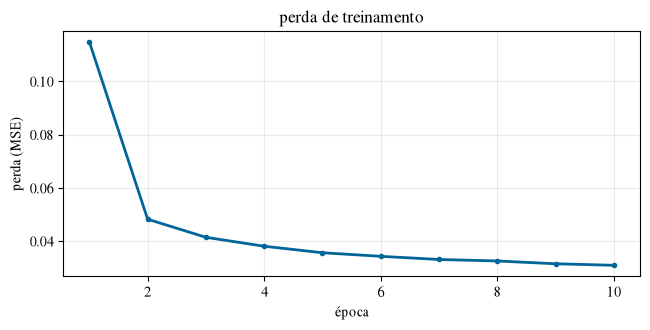

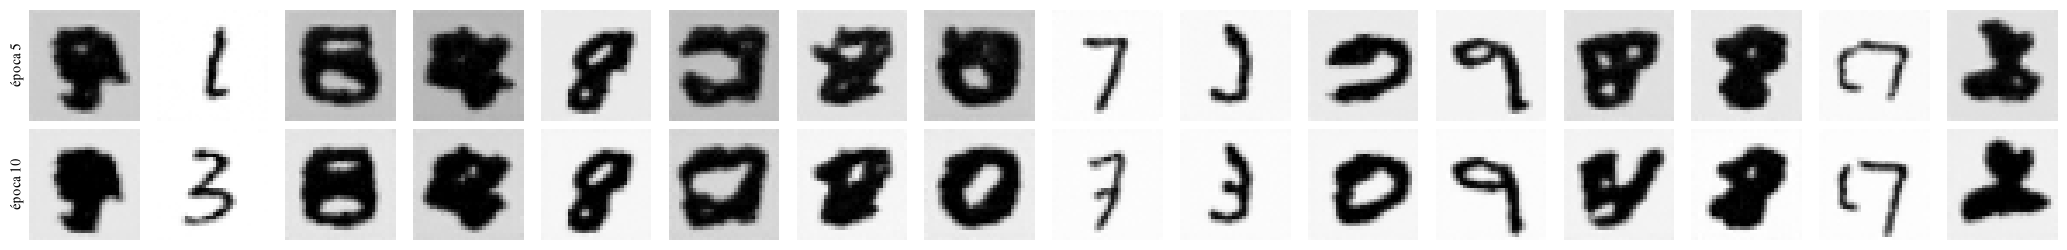

In [22]:

modelo_base, scheduler_base, historico_base = executar_treinamento_mnist(
    beta_schedule="squaredcos_cap_v2",
    train_dl=train_dl,
    tag="BASE",
)

print(f"Perda final: {historico_base.loss[-1]:.6f}")
print(f"Treinamento: {historico_base.train_time / 60:.1f} min")

plot_training_curve(historico_base)
plot_snapshots(historico_base.snapshots)


#### Geração das imagens

  0%|          | 0/1000 [00:00<?, ?it/s]

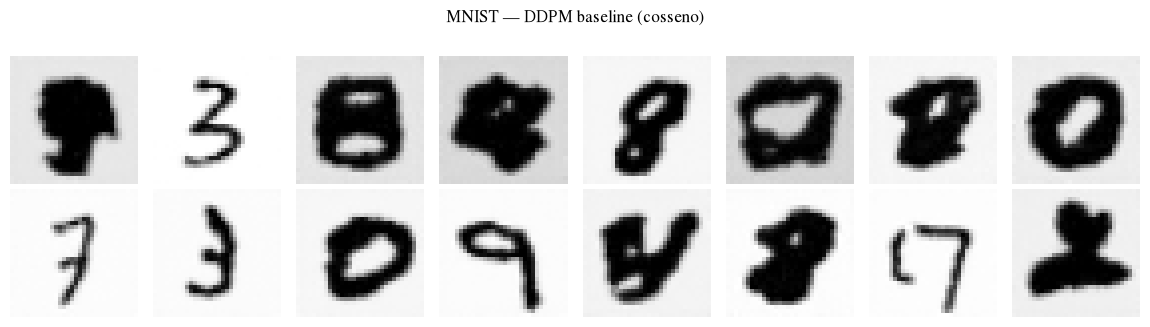

In [23]:

pipeline_base = DDPMPipeline(
    unet=modelo_base,
    scheduler=scheduler_base,
)

generator = torch.Generator().manual_seed(SEED)

imagens_base = pipeline_base(
    batch_size=MNIST_NUM_SAMPLES,
    generator=generator,
    output_type="np",
).images

show_images(
    imagens_base,
    nrows=2,
    suptitle="MNIST — DDPM baseline (cosseno)",
)


#### Processo Reverso

Processo reverso:   0%|          | 0/1000 [00:00<?, ?passo/s]

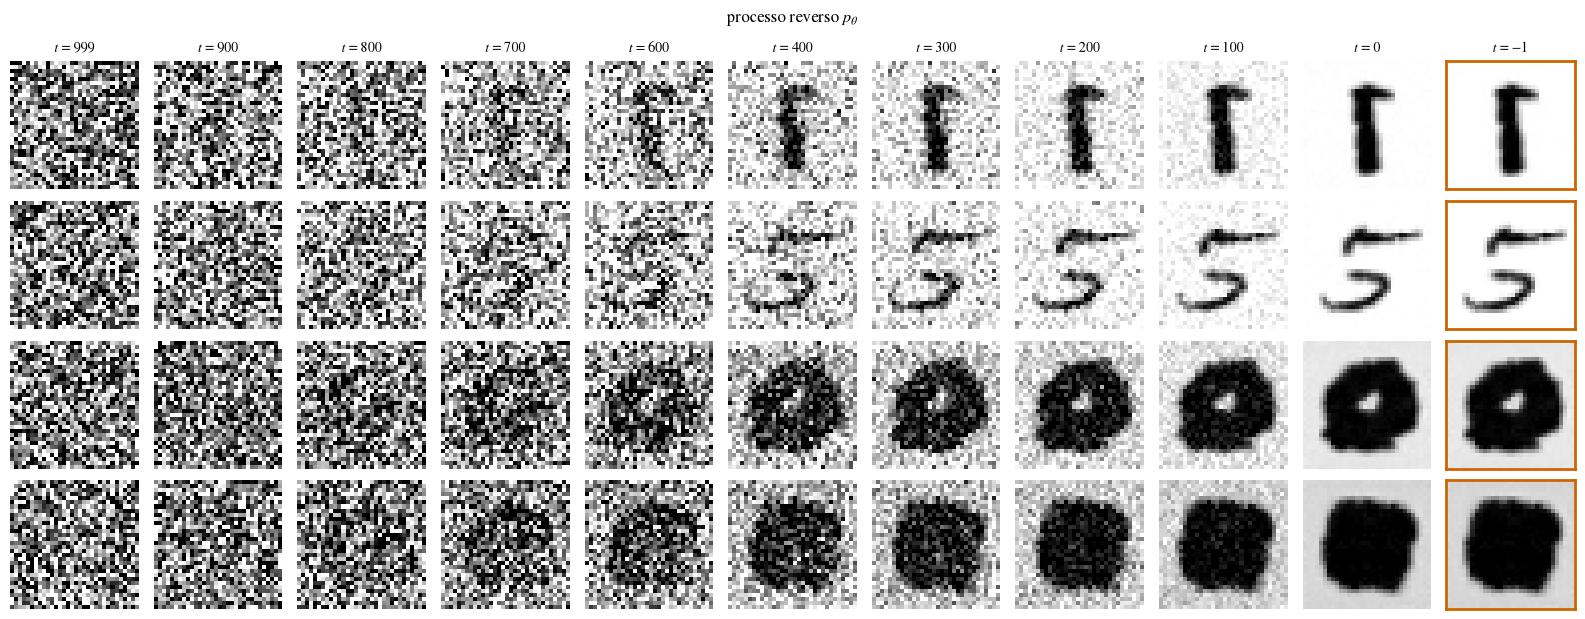

In [24]:
@torch.no_grad()
def executar_processo_reverso(
    model,
    scheduler,
    num_images=4,
    seed=SEED,
):
    """Executa o processo reverso e registra imagens intermediárias."""

    model.eval()
    scheduler.set_timesteps(MNIST_TIMESTEPS)

    generator = torch.Generator().manual_seed(seed)

    x = torch.randn(
        num_images,
        1,
        32,
        32,
        generator=generator,
    ).to(DEVICE)

    snapshots = {}

    for t in tqdm(
        scheduler.timesteps,
        desc="Processo reverso",
        unit="passo",
    ):
        noise_pred = model(x, t).sample

        output = scheduler.step(
            noise_pred,
            t,
            x,
            generator=generator,
        )

        if int(t) % 100 == 0 or int(t) == MNIST_TIMESTEPS - 1:
            snapshots[int(t)] = x.cpu()

        x = output.prev_sample

    snapshots[-1] = x.cpu()

    return snapshots


snapshots_base = executar_processo_reverso(
    modelo_base,
    scheduler_base,
)

plot_reverse_process(snapshots_base)


## 1. Efeito do cronograma de ruído

**Experimento:** treine um modelo novo com o cronograma linear (`beta_schedule="linear"`) e compare-o com o modelo do item 0, que usa o cosseno, fixando os demais parâmetros do baseline. Mostre:

- o processo direto do mesmo dígito com os dois cronogramas (`compare_noise_schedules`);
- as curvas de perda dos dois modelos, sobrepostas e com legenda (`compare_training_curves`);
- para cada modelo, $16$ imagens geradas (`show_images`) e o processo reverso (`plot_reverse_process`);
- a tabela com a perda da última época e a duração do treinamento de cada modelo.

Comente os resultados observados.

### Resposta

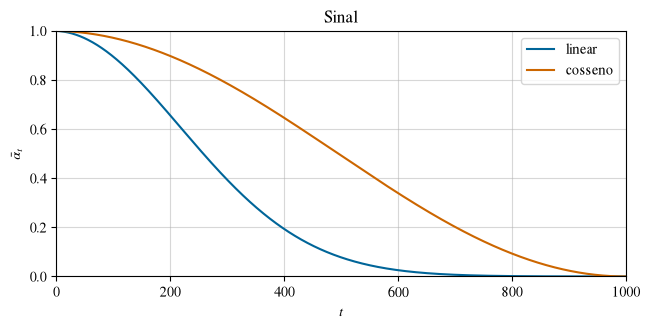

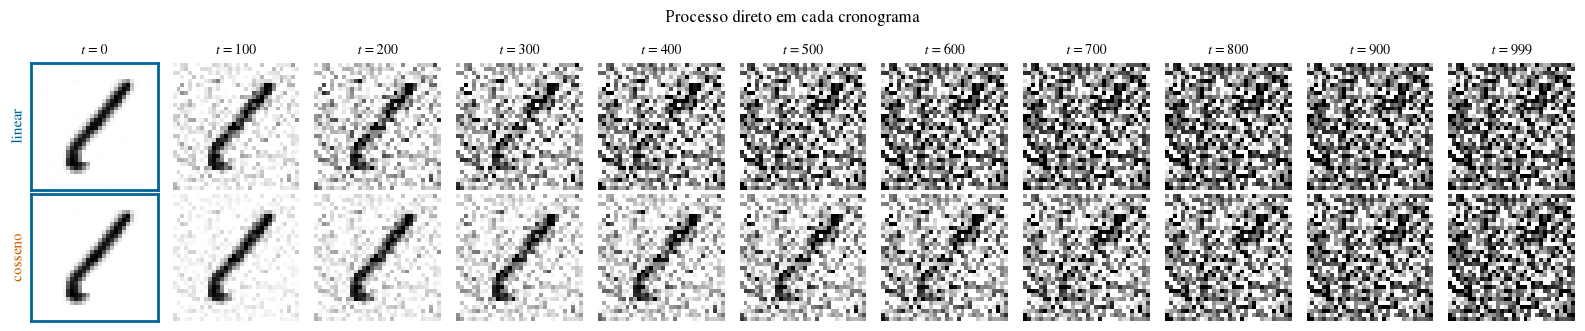

In [25]:

# Compara os processos diretos dos cronogramas linear e cosseno
scheduler_linear = DDPMScheduler(
    num_train_timesteps=MNIST_TIMESTEPS,
    beta_schedule="linear",
    clip_sample=CLIP_SAMPLE,
    variance_type=VARIANCE_TYPE,
)

schedulers = {
    "linear": scheduler_linear,
    "cosseno": scheduler_base,
}

torch.manual_seed(SEED)
x_exemplo = next(iter(train_dl))["images"][0]

compare_noise_schedules(schedulers, x_exemplo)


In [26]:

modelo_linear, scheduler_linear, historico_linear = executar_treinamento_mnist(
    beta_schedule="linear",
    train_dl=train_dl,
    tag="LINEAR",
)

print(f"Perda final (linear): {historico_linear.loss[-1]:.6f}")
print(f"Treinamento (linear): {historico_linear.train_time / 60:.1f} min")


Checkpoint carregado: ddpm_mnist_linear_T1000_E10.pt
Perda final (linear): 0.018405
Treinamento (linear): 12.1 min


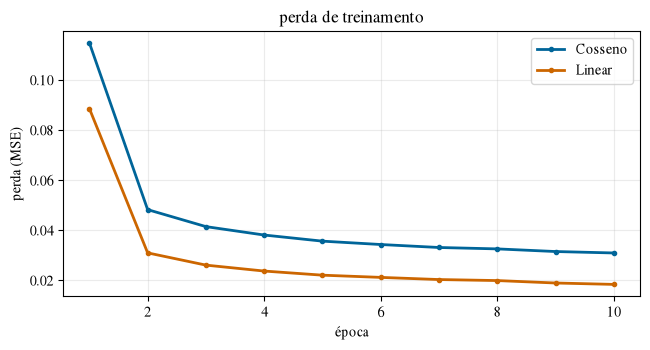

In [27]:
historicos = {
    "Cosseno": historico_base,
    "Linear": historico_linear,
}

compare_training_curves(historicos)

  0%|          | 0/1000 [00:00<?, ?it/s]

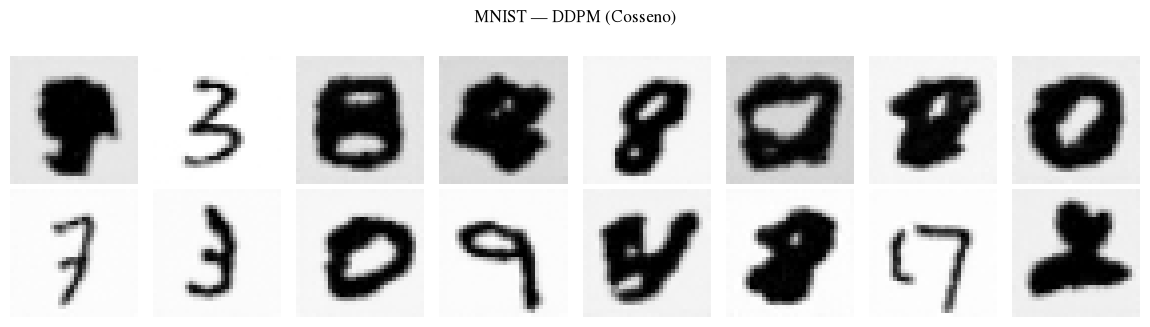

  0%|          | 0/1000 [00:00<?, ?it/s]

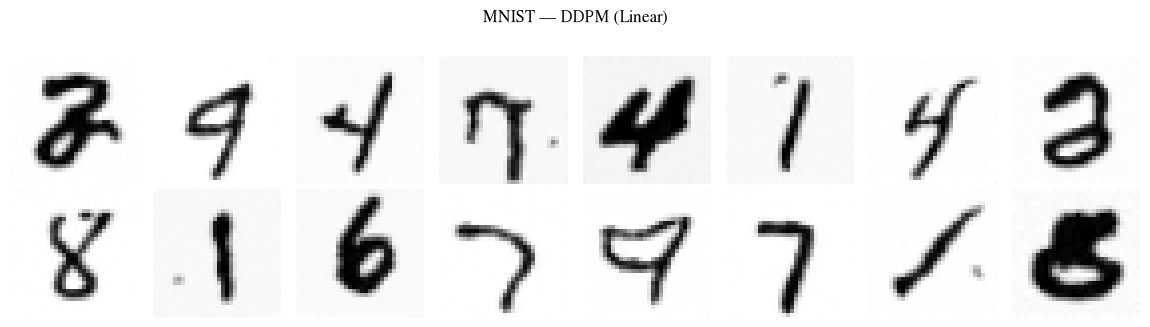

In [28]:

pipeline_linear = DDPMPipeline(
    unet=modelo_linear,
    scheduler=scheduler_linear,
)

for nome, pipeline in [
    ("Cosseno", pipeline_base),
    ("Linear", pipeline_linear),
]:
    generator = torch.Generator().manual_seed(SEED)

    imagens = pipeline(
        batch_size=MNIST_NUM_SAMPLES,
        generator=generator,
        output_type="np",
    ).images

    show_images(
        imagens,
        nrows=2,
        suptitle=f"MNIST — DDPM ({nome})",
    )


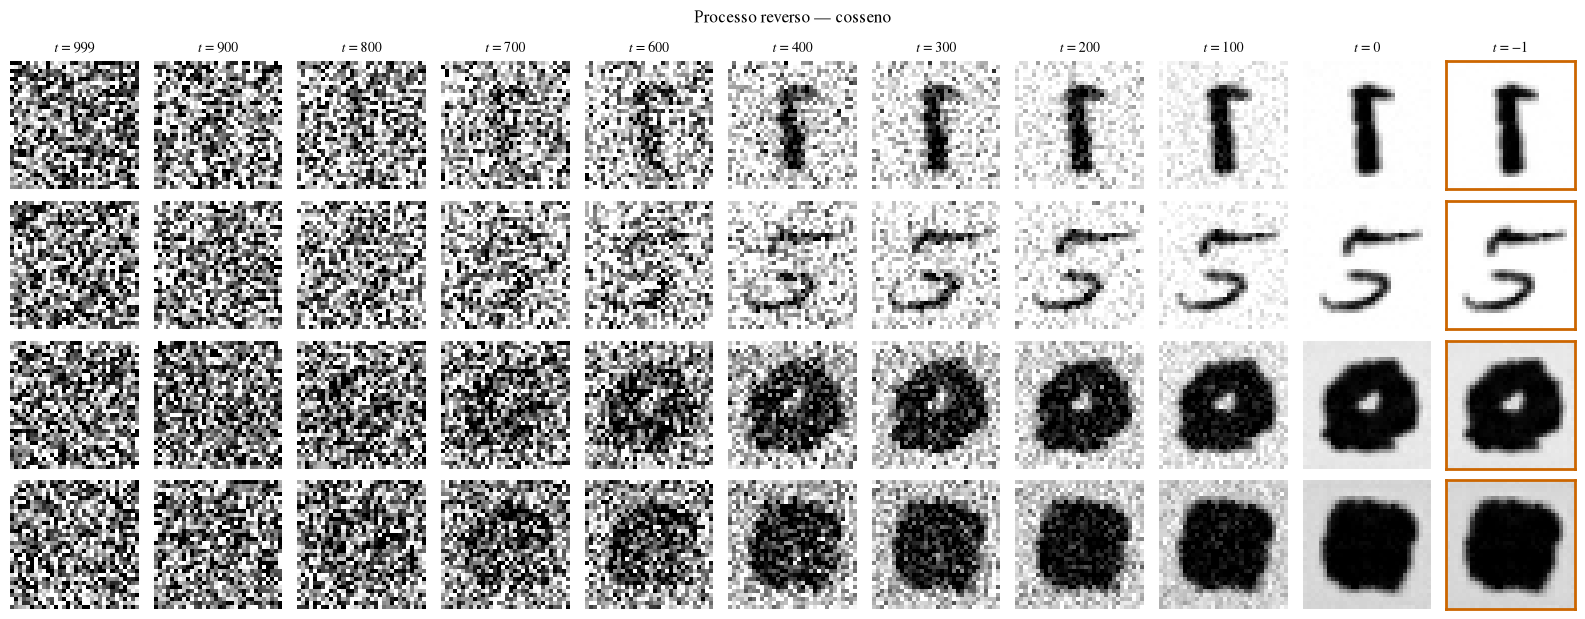

Processo reverso:   0%|          | 0/1000 [00:00<?, ?passo/s]

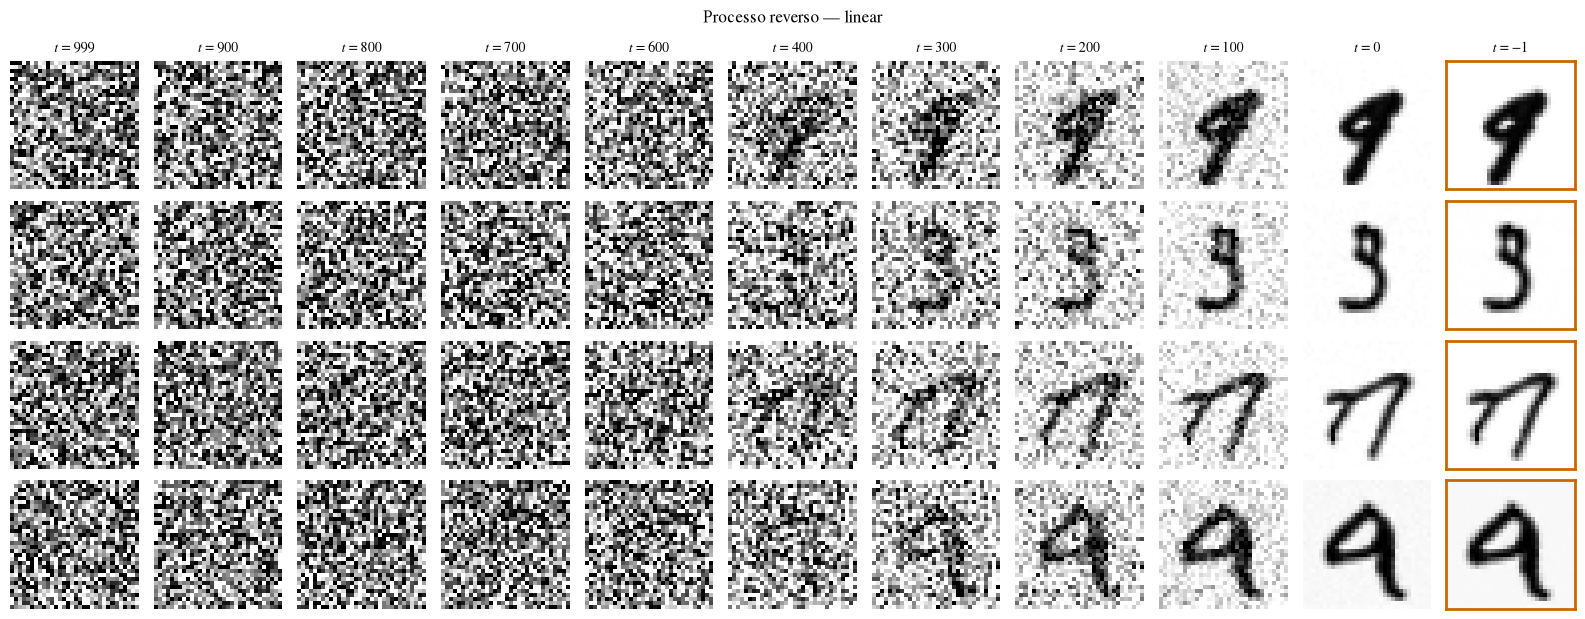

In [29]:

# Processo reverso — cronograma cosseno
plot_reverse_process(
    snapshots_base,
    title="Processo reverso — cosseno",
)

# Processo reverso — cronograma linear
snapshots_linear = executar_processo_reverso(
    modelo_linear,
    scheduler_linear,
)

plot_reverse_process(
    snapshots_linear,
    title="Processo reverso — linear",
)


In [30]:

df_comparacao = pd.DataFrame([
    {
        "Cronograma": "Cosseno",
        "Perda final (MSE)": historico_base.loss[-1],
        "Treinamento (min)": historico_base.train_time / 60,
    },
    {
        "Cronograma": "Linear",
        "Perda final (MSE)": historico_linear.loss[-1],
        "Treinamento (min)": historico_linear.train_time / 60,
    },
])

print(
    df_comparacao.to_string(
        index=False,
        formatters={
            "Perda final (MSE)": "{:.6f}".format,
            "Treinamento (min)": "{:.2f}".format,
        },
    )
)


Cronograma Perda final (MSE) Treinamento (min)
   Cosseno          0.030950             12.19
    Linear          0.018405             12.14


Os resultados mostram que os dois cronogramas de ruído permitiram o aprendizado do processo reverso, com redução consistente da perda ao longo das 10 épocas. Entretanto, o cronograma linear apresentou menor perda final (0,018405) que o cosseno (0,030950), com tempos de treinamento praticamente iguais, próximos de 12,2 minutos.

No processo direto, o cronograma linear adicionou ruído mais rapidamente, enquanto o cosseno preservou as características dos dígitos por mais etapas. Essa diferença influencia o treinamento, pois cada cronograma determina como os níveis de ruído são distribuídos ao longo do processo.

Na comparação visual, ambos conseguiram gerar dígitos reconhecíveis, embora algumas amostras apresentassem deformações. O cronograma linear produziu imagens aparentemente mais definidas em parte das amostras, mas a diferença visual não foi tão expressiva quanto a diferença entre as perdas.

Portanto, o cronograma linear apresentou melhor resultado em termos de perda neste experimento. Entretanto, como os cronogramas produzem distribuições diferentes de ruído ao longo dos passos, a comparação das perdas não é suficiente para determinar qual deles gera imagens de melhor qualidade.

## 2. Número de passos na geração

**Experimento:** com o modelo do item 0, gere $8$ imagens com $S \in \{1000, 250, 50, 10\}$ passos (`pipeline(..., num_inference_steps=S)`), com a mesma semente, e meça a duração de cada geração (`time.perf_counter`). Mostre as imagens numa grade, uma linha por $S$ (`plot_steps_comparison`), e a tabela de durações.

Comente os resultados observados.

### Resposta

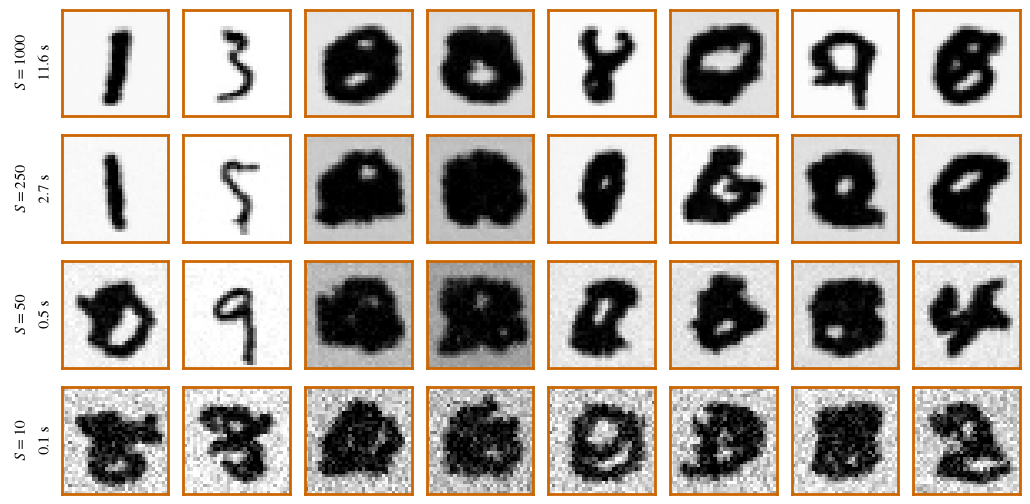

 Passos (S) Duração (s)
       1000       11.63
        250        2.73
         50        0.45
         10        0.09


In [31]:
# Exercício 2 — Número de passos na geração

PASSOS_GERACAO = (1000, 250, 50, 10)
NUM_IMAGENS_COMPARACAO = 8

amostras_passos = {}
duracoes_passos = {}

pipeline_base.set_progress_bar_config(disable=True)

for S in PASSOS_GERACAO:
    generator = torch.Generator().manual_seed(SEED)

    inicio = time.perf_counter()

    amostras_passos[S] = pipeline_base(
        batch_size=NUM_IMAGENS_COMPARACAO,
        generator=generator,
        num_inference_steps=S,
        output_type="np",
    ).images

    duracoes_passos[S] = time.perf_counter() - inicio

plot_steps_comparison(amostras_passos, duracoes_passos)

df_passos = pd.DataFrame([
    {
        "Passos (S)": S,
        "Duração (s)": duracoes_passos[S],
    }
    for S in PASSOS_GERACAO
])

print(
    df_passos.to_string(
        index=False,
        formatters={
            "Duração (s)": "{:.2f}".format,
        },
    )
)


Os resultados mostram que a redução do número de passos de geração (S) diminuiu significativamente o tempo necessário para produzir as imagens. Com S=1000, a geração levou 11,63 segundos, enquanto com S=250 foram necessários apenas 2,73 segundos. Para S=50 e S=10, os tempos caíram para 0,45 e 0,09 segundo, respectivamente.

Entretanto, essa redução também afetou a qualidade das imagens. Com S=1000, os dígitos apresentaram formas relativamente reconhecíveis, embora algumas amostras contivessem deformações. Com S=250, a qualidade visual permaneceu próxima à configuração original, mas com algumas diferenças nos contornos. Já com S=50, houve perda considerável de definição, enquanto S=10 produziu imagens bastante ruidosas, dificultando o reconhecimento dos dígitos.

Portanto, S=250 apresentou um compromisso interessante entre qualidade e desempenho, reduzindo o tempo de geração em aproximadamente 76% em relação a S=1000, sem uma degradação visual tão acentuada. Isso indica que é possível acelerar o processo reverso utilizando menos passos, mas reduções excessivas comprometem a qualidade das imagens geradas.

## 3. Interpolação

**Experimento:** com o modelo do item 0, escolha $4$ pares de dígitos de classes diferentes do conjunto de treinamento (use `labels`) e interpole cada par com $t_{\text{mix}} \in \{1, 250, 500, 750\}$ (`interpolate`). Mostre uma figura por valor de $t_{\text{mix}}$, com os $4$ pares e as imagens originais nas pontas (`plot_interpolation`).

Comente os resultados observados.

### Resposta

In [32]:

# Exercício 3 — Interpolação

PARES_DIGITOS = [(0, 1), (2, 3), (4, 5), (6, 7)]
PASSOS_INTERPOLACAO = (1, 250, 500, 750)

indices_pares = [
    (np.flatnonzero(labels == a)[0], np.flatnonzero(labels == b)[0])
    for a, b in PARES_DIGITOS
]

x0_a = torch.stack([
    mnist[int(i)]["images"]
    for i, _ in indices_pares
])

x0_b = torch.stack([
    mnist[int(j)]["images"]
    for _, j in indices_pares
])

print(f"Pares selecionados: {PARES_DIGITOS}")
print(f"Formato dos lotes: {tuple(x0_a.shape)}")


Pares selecionados: [(0, 1), (2, 3), (4, 5), (6, 7)]
Formato dos lotes: (4, 1, 32, 32)


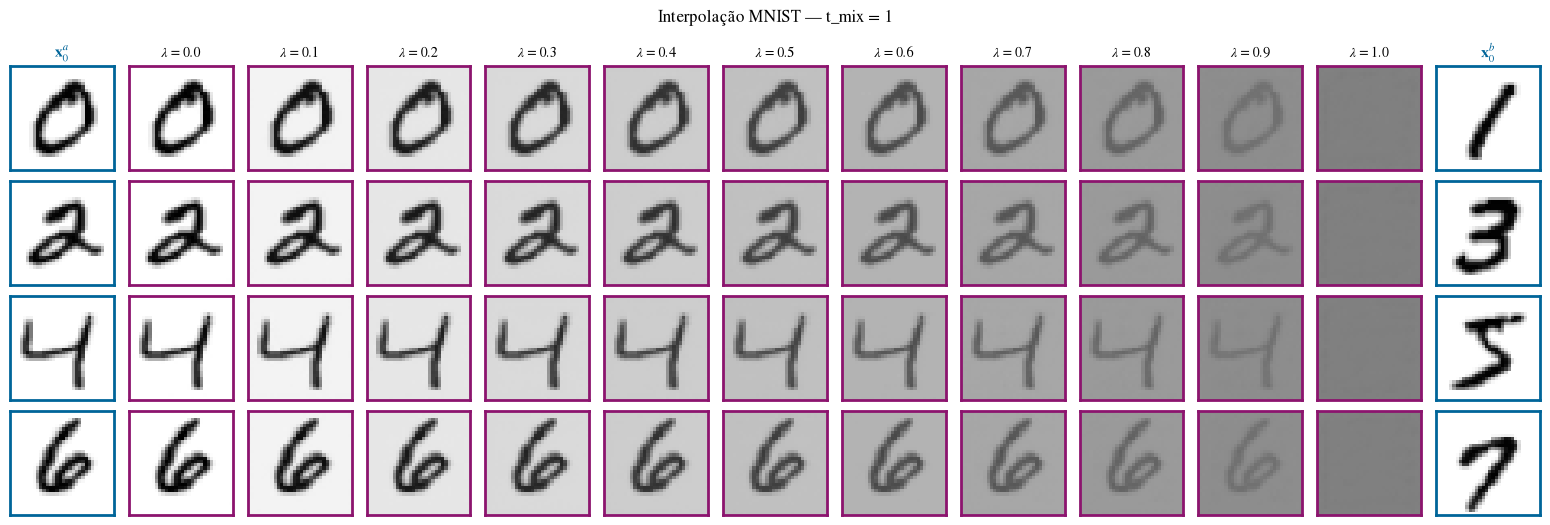

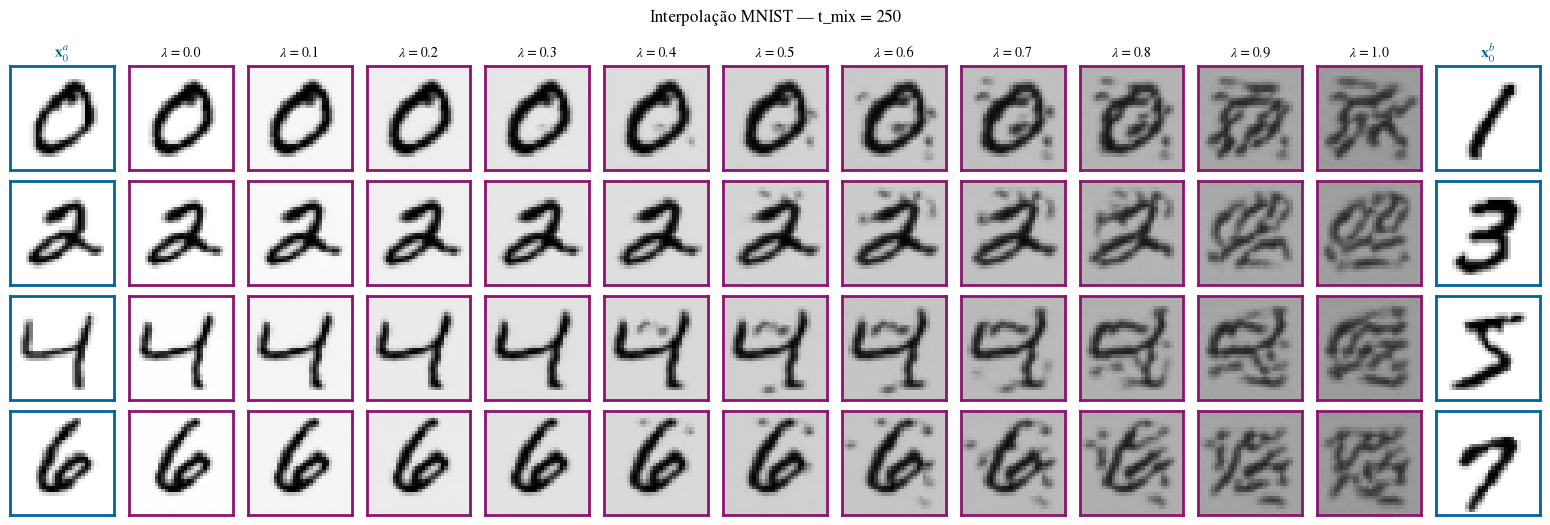

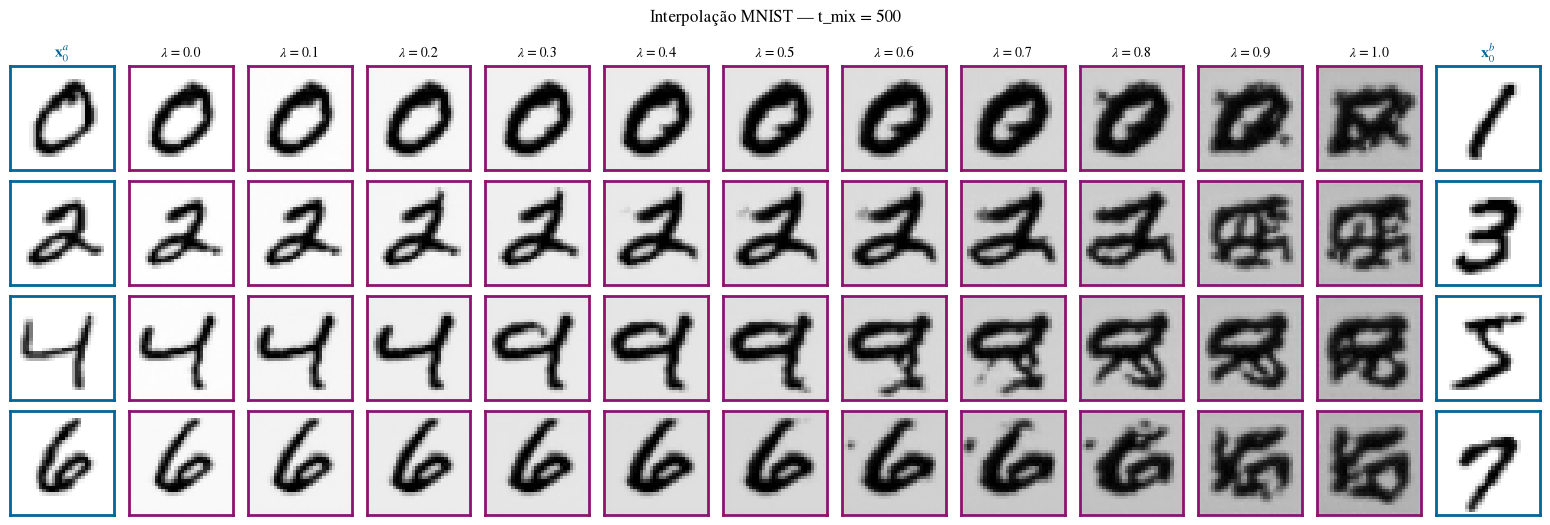

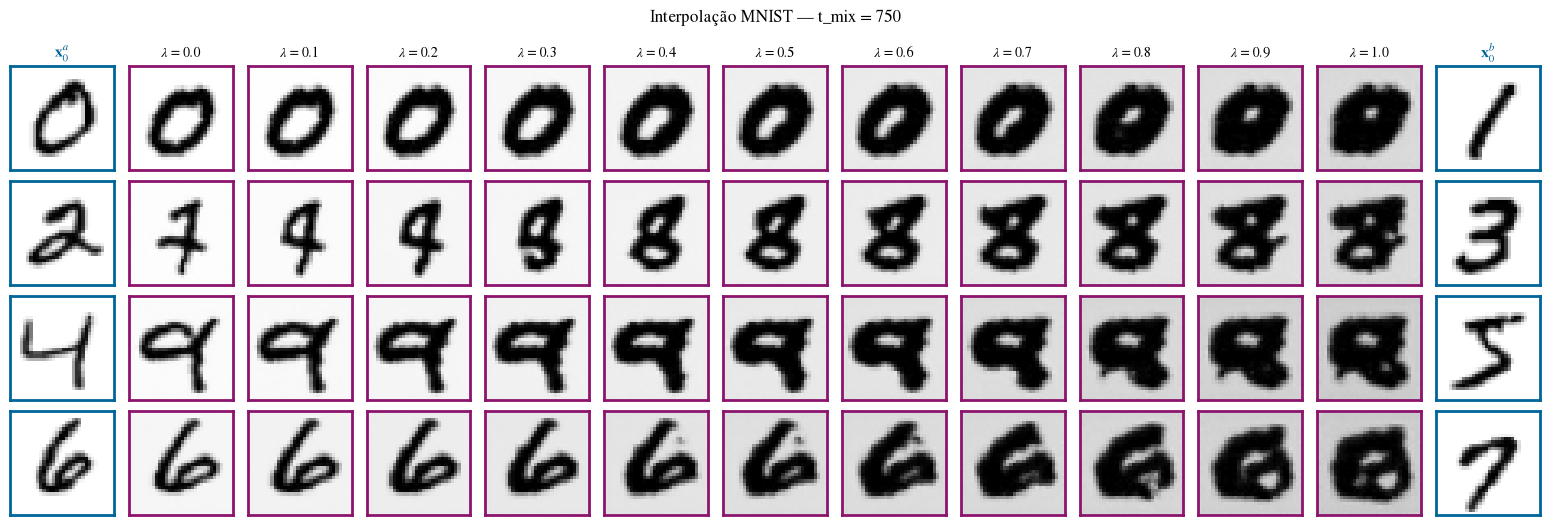

In [56]:
# Interpola os quatro pares para cada valor de t_mix

resultados_interpolacao = {}

for t_mix in PASSOS_INTERPOLACAO:
    frames = interpolate(
        modelo_base,
        scheduler_base,
        x0_a,
        x0_b,
t_mix=t_mix,
num_frames=11,
seed=SEED,
    )

    resultados_interpolacao[t_mix] = frames

    plot_interpolation(
        frames,
        x0_a,
        x0_b,
title=f"Interpolação MNIST — t_mix = {t_mix}",
    )

A execução da interpolação utilizando o acelerador MPS apresentou resultados visualmente inconsistentes, com deformações nas imagens intermediárias e sem chegar a uma imagem final consistente. Após uma investigação inicial, resolvemos testar se comportamento estava relacionado ao dispositivo de execução (MPS). Repetimos o experimento utilizando a CPU, mantendo o mesmo modelo treinado, os parâmetros e a semente aleatória, sem realizar novo treinamento.

Essa segunda execução nos permitiu comparar os resultados entre os dispositivos e avaliar que provavelmente as inconsistências observadas estão associadas à inferência no MPS, muito embora não tenha sido possível determinar a causa raiz do problema.

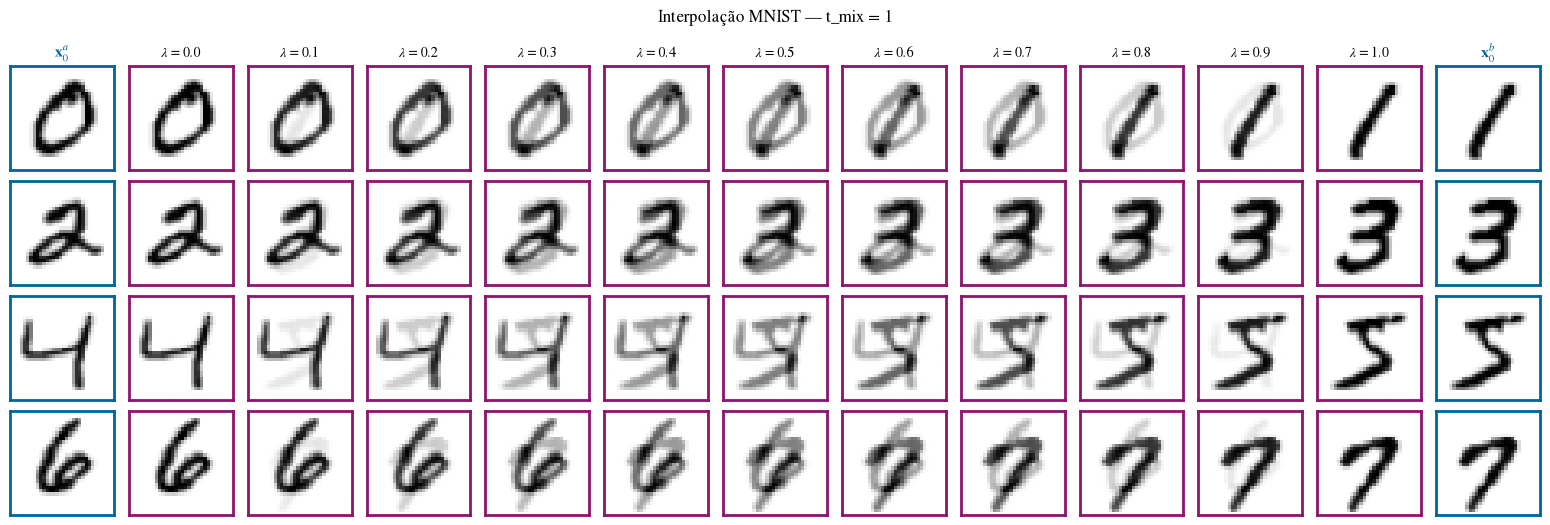

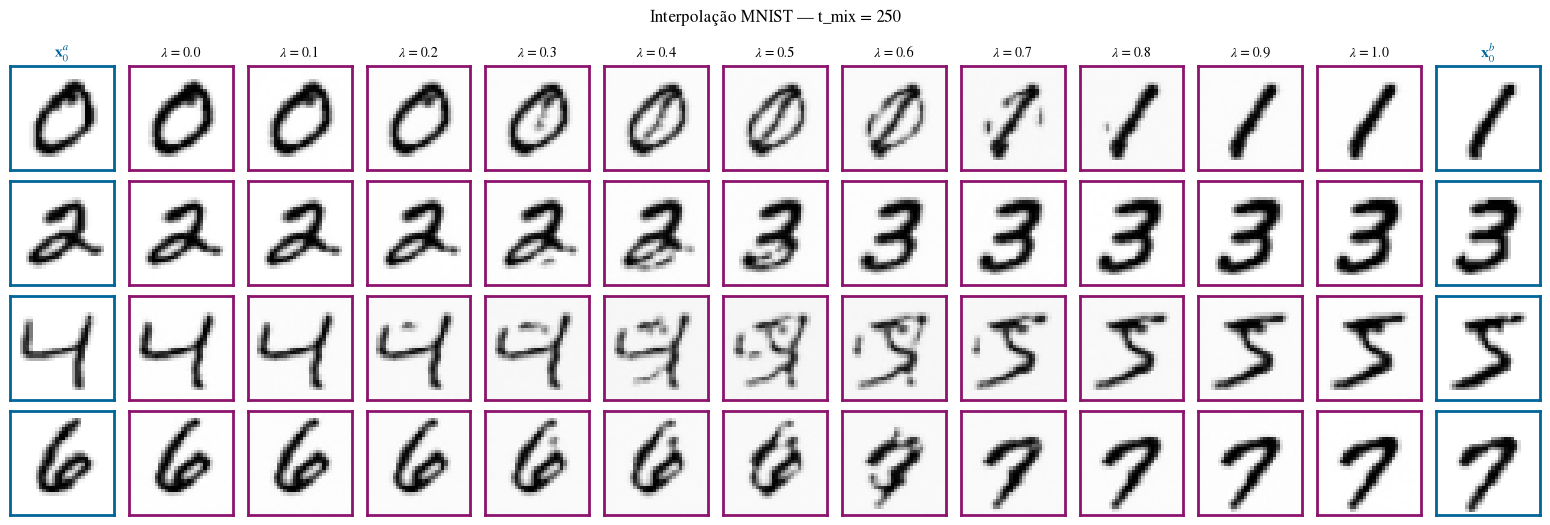

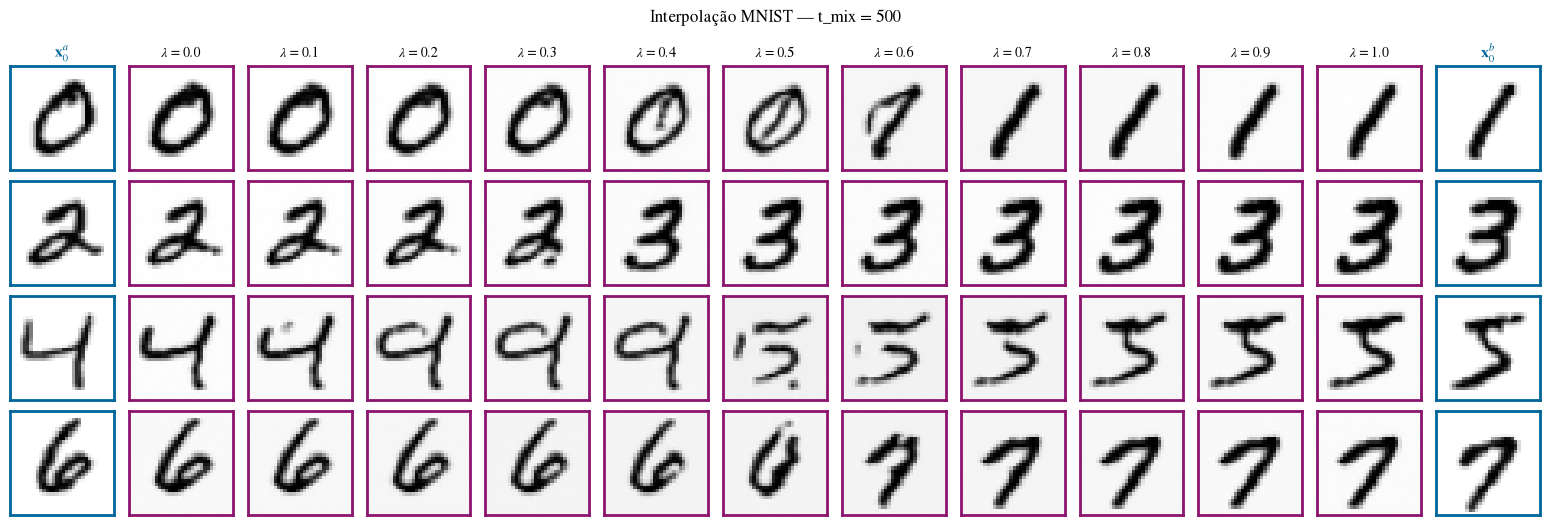

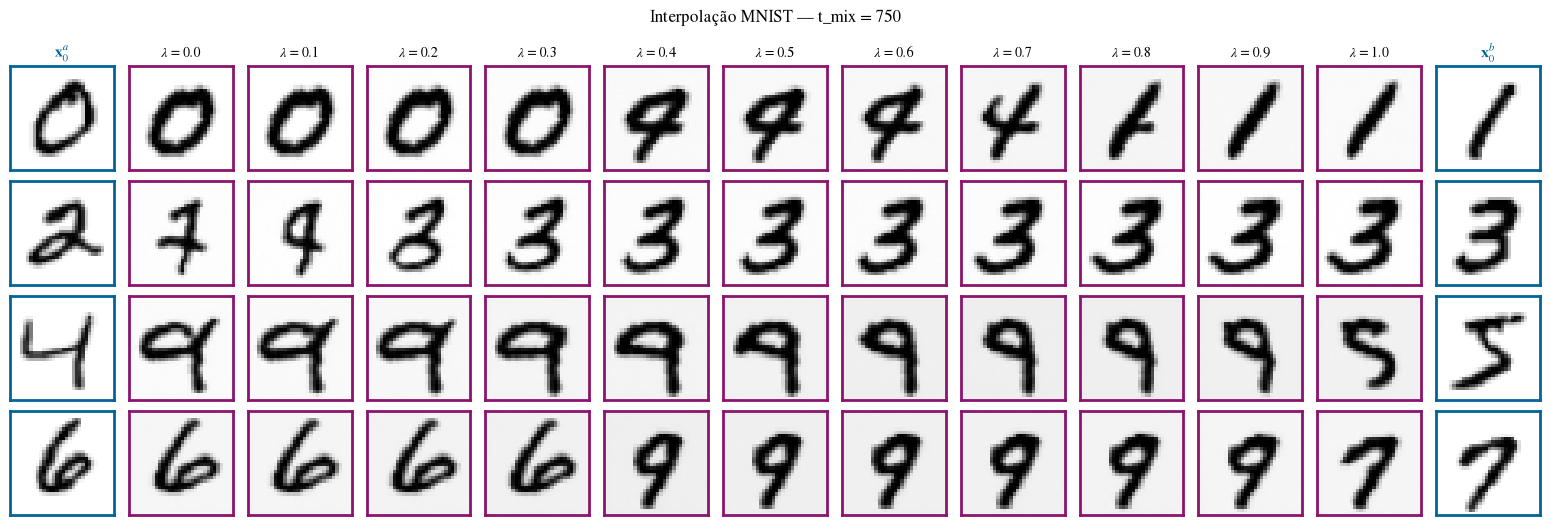

In [55]:
# Interpola os quatro pares para cada valor de t_mix, utilizando a CPU

resultados_interpolacao = {}

dispositivo_original = DEVICE
DEVICE = "cpu"

modelo_base.to(DEVICE)

try:
    for t_mix in PASSOS_INTERPOLACAO:
        frames = interpolate(
            modelo_base,
            scheduler_base,
            x0_a,
            x0_b,
            t_mix=t_mix,
            num_frames=11,
            seed=SEED,
        )

        resultados_interpolacao[t_mix] = frames

        plot_interpolation(
            frames,
            x0_a,
            x0_b,
            title=f"Interpolação MNIST — t_mix = {t_mix}",
        )

finally:
    # Restaura o modelo e o dispositivo original
    DEVICE = dispositivo_original
    modelo_base.to(DEVICE)

O experimento avaliou o efeito de diferentes valores de t_mix na interpolação entre quatro pares de dígitos de classes distintas: (0,1), (2,3), (4,5) e (6,7).

Na primeira execução, utilizando o acelerador MPS, as imagens intermediárias apresentaram resultados inconsistentes, com deformações e dificuldade para reproduzir as transições esperadas. Por esse motivo, repetimos a inferência utilizando a CPU, mantendo o mesmo modelo treinado, os parâmetros e a semente aleatória. Não houve novo treinamento. A segunda execução apresentou resultados visualmente mais coerentes, indicando que o problema poderia estar associado à execução da inferência no MPS, embora não tenha sido possível determinar sua causa exata.

Considerando os resultados obtidos na CPU, com t_mix=1, as transições ocorreram de maneira gradual, preservando as características dos dígitos originais. Com t_mix=250, as transformações também foram progressivas, mas algumas imagens intermediárias apresentaram pequenas deformações.

Para t_mix=500, as mudanças ficaram mais expressivas, com maior alteração das formas e surgimento de imagens intermediárias menos definidas. Já com t_mix=750, observamos transformações ainda mais acentuadas, incluindo formas que se afastaram das características dos dígitos originais e, em alguns casos, se aproximaram de outras classes.

Portanto, os resultados mostram que o aumento de t_mix permite transformações mais amplas, mas também reduz a preservação das características originais e o controle sobre a interpolação. Valores menores produziram transições visualmente mais estáveis, enquanto valores maiores apresentaram maior variabilidade.